# Classification: Logistic Regression

# Table of Contents

### 1. Introduction to Logistic Regression
* **1.1** What is Logistic Regression?

### 2. Binary Logistic Regression
* **2.1** The Need for Probability
* **2.2** The Sigmoid (Logistic) Function
* **2.3** Defining the Model
* **2.4** Interpreting the Weights: Log-Odds
* **2.5** The Decision Boundary
* **2.6** Changing the Threshold Moves the Boundary

### 3. Training: Maximum Likelihood Estimation (MLE)
* **3.1** How Do We Find the Best Parameters?
* **3.2** The Objective Function: Negative Log-Likelihood (NLL)
* **3.3** Why This Loss Function is Good: Convexity

### 4. Derivation of the Gradient
* **4.1** Setup
* **4.2** Step 1: $\partial J/\partial\mu$
* **4.3** Step 2: $\partial\mu/\partial a$
* **4.4** Step 3: $\partial a/\partial w$
* **4.5** The Final Result
* **4.6** Going One Step Further: The Hessian
* **4.7** Proof of Convexity

### 5. Optimization: Finding the Minimum
* **5.1** Gradient Descent
* **5.2** Stochastic Gradient Descent (SGD)
* **5.3** Implementing Logistic Regression in Python
* **5.4** A Mind Experiment: Why the Gradient is so Important

### 6. Worked Example: Maximum Likelihood by Hand
* **6.1** The Spam Filter
* **6.2** What the Solution Tells Us
* **6.3** Checking the Solution in Python

### 7. Separable vs. Non-Separable Data
* **7.1** Solution Behaviour
* **7.2** Worked Example, Part 2: A Perfect Predictor
* **7.3** L2 Regularization Restores a Unique, Finite Solution
* **7.4** Exploding Weights in Python

### 8. Handling Nonlinearity
* **8.1** Feature Transformations
* **8.2** The Problem of Overfitting

### 9. Multinomial Logistic Regression
* **9.1** The Softmax Function
* **9.2** The Gradient for Softmax Regression
* **9.3** Softmax Regression in Python

### 10. Naive Bayes Classifier
* **10.1** Generative vs. Discriminative
* **10.2** The Naive Bayes Assumption
* **10.3** The Naive Bayes Model
* **10.4** Fitting a Naive Bayes Classifier
* **10.5** Gaussian Naive Bayes in Python
* **10.6** Generative vs. Discriminative Classifiers

### 11. Evaluating Classification Models
* **11.1** Why Accuracy Can Be Misleading
* **11.2** The Confusion Matrix
* **11.3** Precision and Recall
* **11.4** Precision vs. Recall: The Trade-off
* **11.5** ROC Curve and AUC

 # ------------------------------------------------------------------------------

# 1. Introduction to Logistic Regression

## 1.1 What is Logistic Regression?

In [1]:
# imports init
import numpy as np
import matplotlib.pyplot as plt

Logistic regression is a widely used **discriminative** classification model. It models the probability of a class label $y$ given an input vector $x$, written as $p(y|x;\theta)$, where the parameters of the model are represented by $\theta$. It is a foundational method for classification tasks and serves as a building block for more complex models like neural networks.

There are two versions:
* **Binary Logistic Regression:** used when there are two classes ($C = 2$), e.g. spam/not-spam.
* **Multinomial Logistic Regression:** used when there are more than two classes ($C > 2$), e.g. cat/dog/bird.

# 2. Binary Logistic Regression

## 2.1 The Need for Probability

Recall that Linear Regression outputs a continuous value, e.g. $y = w^Tx + b$. This output can be any real number in $(-\infty,\infty)$, which is not suitable for classification. For classification, we want a **probability**: a value between $0$ and $1$.

So the goal is to map the linear output $w^Tx + b$ to a valid probability:
$$
\text{Linear Output} \xrightarrow{\text{squashing function}} \text{Probability}
$$

## 2.2 The Sigmoid (Logistic) Function

The sigmoid function $\sigma(a)$ is the perfect tool for this "squashing":
$$
\sigma(a) = \frac{1}{1 + e^{-a}}
$$
* It maps any real number $a$ to the range $(0,1)$.
* It is interpretable as a probability.
* It is differentiable, which is crucial for training with gradient descent.

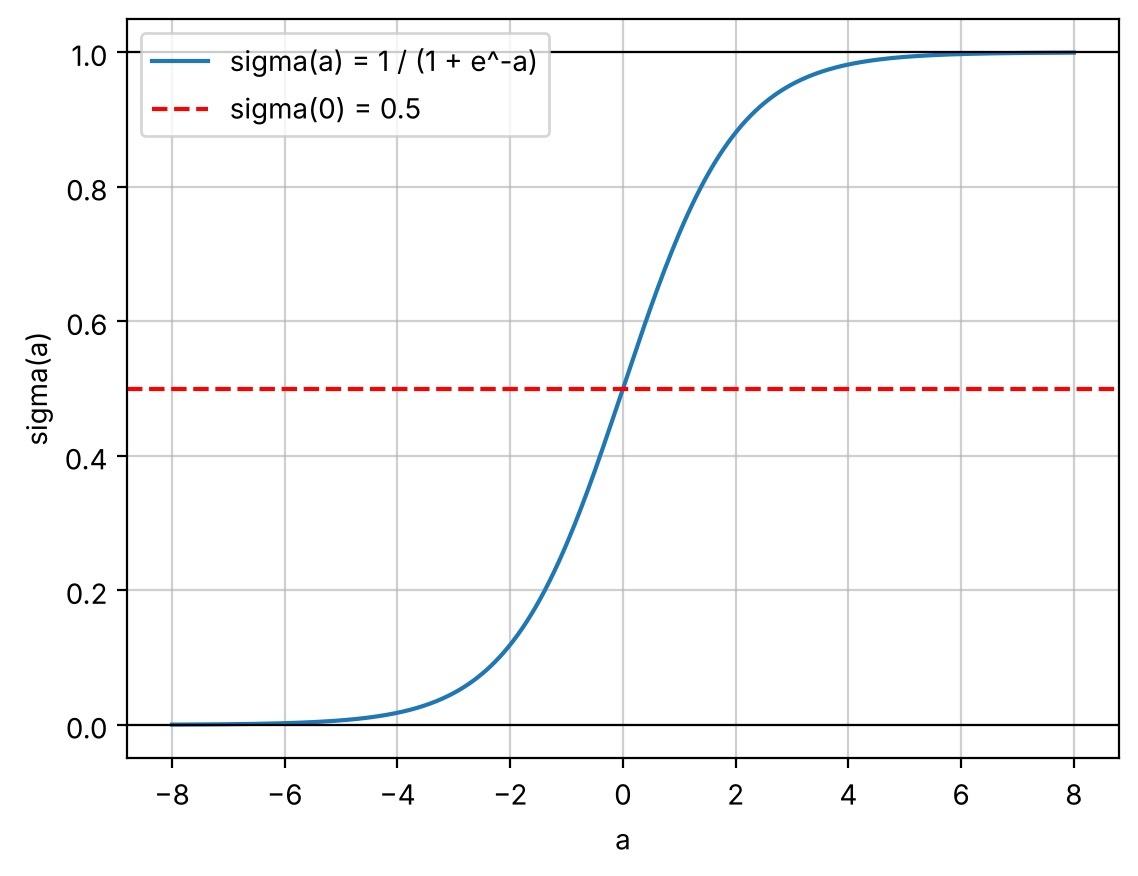

In [2]:
def sigmoid(a):
    # clipping a avoids overflow in exp for very large logits (sigma is already 0 or 1 there)
    return 1 / (1 + np.exp(-np.clip(a, -500, 500)))

a = np.linspace(-8, 8, 400)
plt.plot(a, sigmoid(a), label="sigma(a) = 1 / (1 + e^-a)")
plt.axhline(0.5, color="red", linestyle="--", label="sigma(0) = 0.5")
plt.axhline(0, color="black", linewidth=0.8)
plt.axhline(1, color="black", linewidth=0.8)
plt.xlabel("a")
plt.ylabel("sigma(a)")
plt.legend()
plt.grid(True, alpha=0.6)

## 2.3 Defining the Model

Binary logistic regression models the probability of a class as a **Bernoulli distribution**, governed by the sigmoid of a linear function of the inputs. The probability of the positive class ($y = 1$) is:
$$
p(y = 1|x,\theta) = \sigma(w^Tx + b) = \frac{1}{1 + e^{-(w^Tx + b)}}
$$
where $\theta = (w,b)$ are the model parameters (weights and bias).

The quantity $a = w^Tx + b$ is called the **logit** or **pre-activation**:
* If $a \to \infty$, then $\sigma(a) \to 1$.
* If $a \to -\infty$, then $\sigma(a) \to 0$.
* If $a = 0$, then $\sigma(a) = 0.5$.

## 2.4 Interpreting the Weights: Log-Odds

The **odds** of the positive class are $\mu/(1-\mu)$, where $\mu = p(y=1|x,\theta)$. With $a = w^Tx + b$:
$$
\frac{\sigma(a)}{1 - \sigma(a)} = \frac{1/(1+e^{-a})}{e^{-a}/(1+e^{-a})} = e^{a}
$$
Taking the log of both sides, we see that logistic regression is **linear in the log-odds**:
$$
\log\frac{p(y=1|x,\theta)}{p(y=0|x,\theta)} = w^Tx + b
$$
The logit is the inverse of the sigmoid: $a = \sigma^{-1}(\mu) = \log\frac{\mu}{1-\mu}$.
* Increasing $x_j$ by one unit adds $w_j$ to the log-odds, so it multiplies the odds by $e^{w_j}$ (an **odds ratio**).
* $w_j > 0$ favours $y = 1$, $w_j < 0$ favours $y = 0$, and $w_j = 0$ means no effect.

## 2.5 The Decision Boundary

To make a classification, we predict $y = 1$ if it is more likely than $y = 0$:
$$
\text{Predict } y = 1 \quad \text{if} \quad p(y=1|x) > 0.5
$$
Since $\sigma(a) > 0.5 \iff a > 0$, the boundary that separates the two classes is a **linear hyperplane** defined by the equation:
$$
w^Tx + b = 0
$$
This plane separates the feature space into two half-spaces, and $w$ is the normal vector to the plane.

## 2.6 Changing the Threshold Moves the Boundary

More generally, we predict $y = 1$ when $p(y=1|x) \geq \tau$, for a threshold $\tau \in (0,1)$. Since $\sigma$ is strictly increasing:
$$
\sigma(w^Tx + b) \geq \tau \iff w^Tx + b \geq \log\frac{\tau}{1-\tau}
$$
* The normal vector $w$ stays the same, so changing $\tau$ only shifts the boundary parallel to itself, by $\log\frac{\tau}{1-\tau}/\|w\|$.
* A lower $\tau$ gives more predicted positives (higher recall). A higher $\tau$ gives fewer (higher precision).

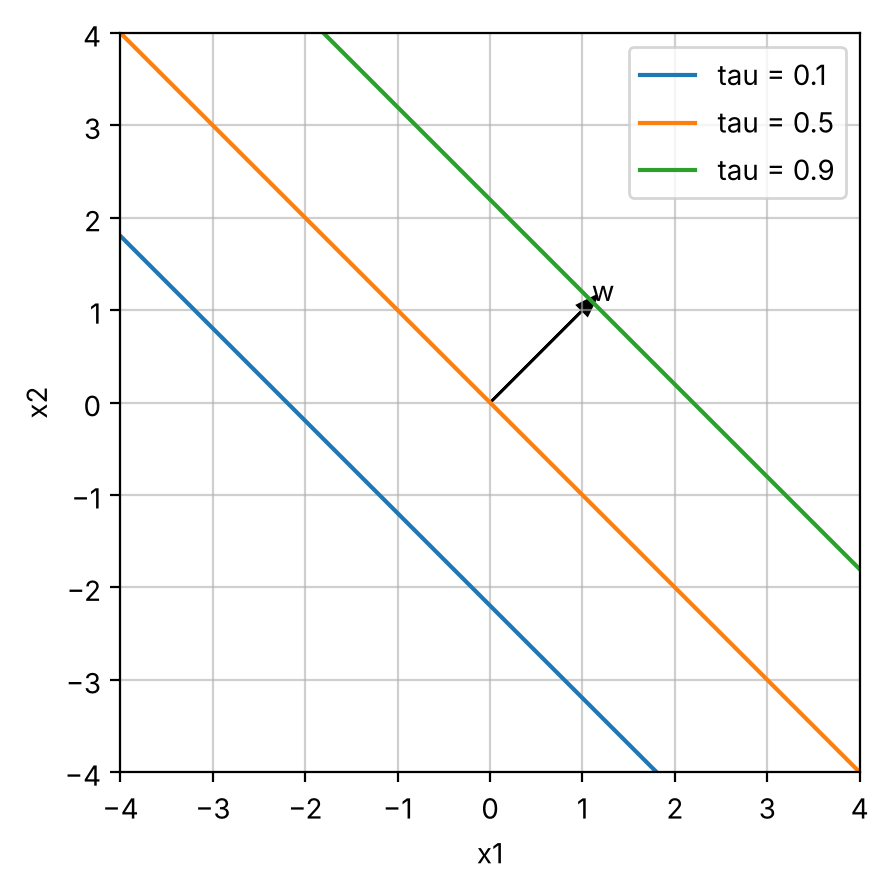

In [3]:
# a fixed model in 2D, w = (1, 1), b = 0
w = np.array([1.0, 1.0])
b = 0.0

x1 = np.linspace(-4, 4, 100)
for tau in [0.1, 0.5, 0.9]:
    # boundary: w1 x1 + w2 x2 + b = log(tau / (1 - tau))  =>  solve for x2
    shift = np.log(tau / (1 - tau))
    x2 = (shift - b - w[0]*x1) / w[1]
    plt.plot(x1, x2, label=f"tau = {tau}")

plt.arrow(0, 0, w[0], w[1], head_width=0.15, color="black")
plt.text(1.1, 1.1, "w")
plt.xlabel("x1")
plt.ylabel("x2")
plt.xlim(-4, 4)
plt.ylim(-4, 4)
plt.gca().set_aspect("equal")
plt.legend()
plt.grid(True, alpha=0.6)

# 3. Training: Maximum Likelihood Estimation (MLE)

## 3.1 How Do We Find the Best Parameters?

We need an objective function to optimise. The standard method for logistic regression is **Maximum Likelihood Estimation (MLE)** (see Week 2).
* **Goal:** find the parameters $\theta = (w,b)$ that maximise the probability of observing our labelled training data $D = \{(x_n,y_n)\}_{n=1}^{N}$.
* We assume the training examples are independent and identically distributed (i.i.d.).

Therefore, the total likelihood is the product of the probabilities of each data point:
$$
p(D|\theta) = \prod_{n=1}^{N}p(y_n|x_n,\theta)
$$

## 3.2 The Objective Function: Negative Log-Likelihood (NLL)

Products are hard to optimise, so it is easier to work with the log-likelihood, which turns products into sums:
$$
\log p(D|\theta) = \sum_{n=1}^{N}\log p(y_n|x_n,\theta)
$$
Let $\mu_n = \sigma(w^Tx_n + b)$. Since $y_n$ is Bernoulli, we can write both cases in one line (like the coin in Week 2):
$$
p(y_n|x_n,\theta) = \mu_n^{y_n}(1-\mu_n)^{1-y_n}
$$
So the log-likelihood for one point is:
$$
\log p(y_n|\cdot) = y_n\log\mu_n + (1-y_n)\log(1-\mu_n)
$$

### The NLL Loss Function
Maximising the log-likelihood is equivalent to minimising the **Negative Log-Likelihood (NLL)**. Averaged over the dataset, this is our loss function:
$$
\text{NLL}(\theta) = -\frac{1}{N}\sum_{n=1}^{N}\left[y_n\log\mu_n + (1-y_n)\log(1-\mu_n)\right]
$$
This is also known as the **binary cross-entropy loss**.

## 3.3 Why This Loss Function is Good: Convexity

The Negative Log-Likelihood for logistic regression is a **convex** function.
* It has a "bowl shape": every local minimum is a global minimum. There are no bad local minima to get stuck in.
* Gradient-based methods can find the best parameters, if a minimum exists (we prove this with the Hessian in Section 4.7).

We can plot the loss surface for a model with one feature and a bias, to see the bowl shape.

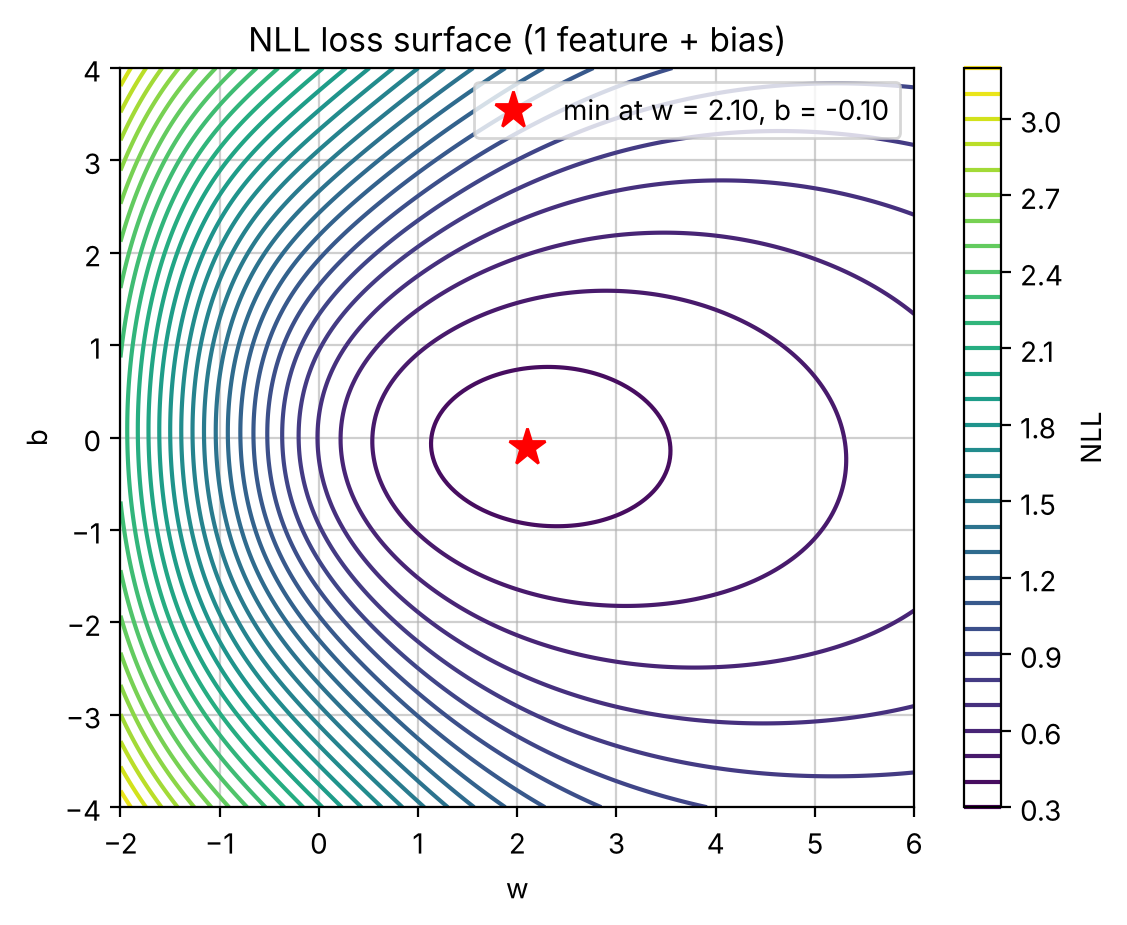

In [4]:
# first we make some 1D data with overlapping classes
rng = np.random.default_rng(0)
N = 100
x = np.concatenate([rng.normal(-1, 1, N//2), rng.normal(1, 1, N//2)])
y = np.concatenate([np.zeros(N//2), np.ones(N//2)])

def nll(w, b, x, y):
    mu = sigmoid(w*x + b)
    eps = 1e-12   # avoids log(0)
    return -np.mean(y*np.log(mu + eps) + (1 - y)*np.log(1 - mu + eps))

# next we evaluate the NLL on a grid of (w, b) values
W, B = np.meshgrid(np.linspace(-2, 6, 200), np.linspace(-4, 4, 200))
L = np.vectorize(lambda w, b: nll(w, b, x, y))(W, B)
i_min = np.unravel_index(np.argmin(L), L.shape)

plt.contour(W, B, L, levels=30)
plt.colorbar(label="NLL")
plt.plot(W[i_min], B[i_min], "r*", markersize=14, label=f"min at w = {W[i_min]:.2f}, b = {B[i_min]:.2f}")
plt.xlabel("w")
plt.ylabel("b")
plt.title("NLL loss surface (1 feature + bias)")
plt.legend()
plt.grid(True, alpha=0.6)

# 4. Derivation of the Gradient

## 4.1 Setup

Our goal is to find the gradient of the NLL for a single data point, $J(\theta)$, with respect to the weights $w$ (we absorb the bias into $w$ by adding a constant feature $x_0 = 1$, so $a = w^Tx$):
$$
J(\theta) = -\left[y\log\mu + (1-y)\log(1-\mu)\right]
$$
We have a chain of dependencies:
* The loss $J$ depends on the prediction $\mu$.
* The prediction $\mu$ depends on the logit $a$, ($\mu = \sigma(a)$).
* The logit $a$ depends on the weights $w$, ($a = w^Tx$).

So we use the **chain rule** to combine these dependencies:
$$
\frac{\partial J}{\partial w} = \frac{\partial J}{\partial\mu}\frac{\partial\mu}{\partial a}\frac{\partial a}{\partial w}
$$

## 4.2 Step 1: $\partial J/\partial\mu$

First, we find the derivative of the loss $J$ with respect to the prediction $\mu$:
$$
\begin{align*}
\frac{\partial J}{\partial\mu} &= -\left[y\frac{1}{\mu} + (1-y)\frac{1}{1-\mu}(-1)\right] \\
&= -\left[\frac{y}{\mu} - \frac{1-y}{1-\mu}\right] \\
&= -\frac{y(1-\mu) - \mu(1-y)}{\mu(1-\mu)} && (\text{common denominator}) \\
&= -\frac{y - \mu}{\mu(1-\mu)} && (\text{since } y - y\mu - \mu + \mu y = y - \mu) \\
&= \frac{\mu - y}{\mu(1-\mu)}
\end{align*}
$$
**Result 1:**
$$
\frac{\partial J}{\partial\mu} = \frac{\mu - y}{\mu(1-\mu)}
$$

## 4.3 Step 2: $\partial\mu/\partial a$

Second, we find the derivative of the sigmoid $\mu = \sigma(a) = (1+e^{-a})^{-1}$ with respect to its input $a$.

### Proof
$$
\begin{align*}
\frac{d\sigma}{da} &= -(1+e^{-a})^{-2}\cdot(-e^{-a}) && (\text{chain rule}) \\
&= \frac{e^{-a}}{(1+e^{-a})^2} \\
&= \frac{1}{1+e^{-a}}\cdot\frac{e^{-a}}{1+e^{-a}} && (\text{split the fraction}) \\
&= \sigma(a)\left(1 - \sigma(a)\right) && (\text{since } \tfrac{e^{-a}}{1+e^{-a}} = 1 - \tfrac{1}{1+e^{-a}})
\end{align*}
$$
**Result 2:**
$$
\frac{\partial\mu}{\partial a} = \sigma(a)(1-\sigma(a)) = \mu(1-\mu)
$$
(This is a standard result worth remembering!)

## 4.4 Step 3: $\partial a/\partial w$

Third, we find the derivative of the logit $a = w^Tx = \sum_{j=1}^{D}w_jx_j$ with respect to the weights $w$. The partial derivative with respect to a single weight $w_j$ is simply its corresponding feature value:
$$
\frac{\partial a}{\partial w_j} = x_j
$$
In vector notation, the gradient of $a$ with respect to the entire weight vector $w$ is the input vector $x$.

**Result 3:**
$$
\nabla_w a = \frac{\partial a}{\partial w} = x
$$

## 4.5 The Final Result

Finally, we combine all three parts using the chain rule and substitute the results:
$$
\begin{align*}
\nabla_w J &= \frac{\partial J}{\partial\mu}\frac{\partial\mu}{\partial a}\frac{\partial a}{\partial w} \\
&= \left(\frac{\mu - y}{\mu(1-\mu)}\right)\cdot\left(\mu(1-\mu)\right)\cdot(x) && (\text{Results 1, 2 and 3}) \\
&= (\mu - y)x && (\text{the } \mu(1-\mu) \text{ terms cancel out})
\end{align*}
$$
So the gradient for one sample is:
$$
\nabla_w J = (\mu - y)x = (\text{prediction} - \text{actual}) \times \text{input}
$$
For the entire dataset, we average this gradient:
$$
\nabla_w\text{NLL}(w) = \frac{1}{N}\sum_{n=1}^{N}(\mu_n - y_n)x_n = \frac{1}{N}X^T(\mu - y)
$$
Where:
$$\begin{align}
    &X \text{: is the } N \times D \text{ design matrix (rows } x_n^T\text{)} \\
    &\mu \text{: is the vector of predictions } \mu_n = \sigma(w^Tx_n) \\
    &y \text{: is the vector of labels}
\end{align}
$$

We can check this formula numerically, by comparing it with a finite difference approximation of the gradient.

In [5]:
rng = np.random.default_rng(1)

# first we create a small random problem, the first column of X is the bias feature
N, D = 20, 3
X = np.column_stack([np.ones(N), rng.normal(size=(N, D-1))])
y = rng.integers(0, 2, size=N).astype(float)
w = rng.normal(size=D)

def nll_vec(w, X, y):
    mu = sigmoid(X @ w)
    return -np.mean(y*np.log(mu) + (1 - y)*np.log(1 - mu))

def grad_nll(w, X, y):
    # (1/N) X^T (mu - y)
    return X.T @ (sigmoid(X @ w) - y) / len(y)

# next we approximate each partial derivative with a central difference
h = 1e-6
numerical = np.array([(nll_vec(w + h*e, X, y) - nll_vec(w - h*e, X, y)) / (2*h) for e in np.eye(D)])

print("--- Gradient Check ---")
print(f"Analytic  (1/N) X^T (mu - y) : {grad_nll(w, X, y)}")
print(f"Numerical finite difference  : {numerical}")
print(f"Max difference               : {np.max(np.abs(grad_nll(w, X, y) - numerical)):.2e}")

--- Gradient Check ---
Analytic  (1/N) X^T (mu - y) : [-0.12600351 -0.01033652  0.00118383]
Numerical finite difference  : [-0.12600351 -0.01033652  0.00118383]
Max difference               : 3.98e-11


## 4.6 Going One Step Further: The Hessian

Earlier we claimed the NLL is convex. To prove it, we differentiate the gradient $\nabla_w\text{NLL}(w) = \frac{1}{N}\sum_n(\mu_n - y_n)x_n$ once more, with $\mu_n = \sigma(w^Tx_n)$.

Only $\mu_n$ depends on $w$, and Results 2 and 3 give $\nabla_w\mu_n = \mu_n(1-\mu_n)x_n$. So:
$$
H(w) = \nabla_w^2\text{NLL}(w) = \frac{1}{N}\sum_{n=1}^{N}\mu_n(1-\mu_n)x_nx_n^T = \frac{1}{N}X^TSX
$$
Where:
$$\begin{align}
    &X \text{: is the design matrix (rows } x_n^T\text{)} \\
    &S = \text{diag}\left(\mu_n(1-\mu_n)\right) \text{: is a diagonal matrix of weights}
\end{align}
$$
**Compare with least squares:** there the Hessian is proportional to $X^TX$ for every $w$. Here example $n$ is reweighted by $\mu_n(1-\mu_n) \in (0,\frac{1}{4}]$, most when the prediction is uncertain ($\mu_n \approx 0.5$).

## 4.7 Proof of Convexity

### Theorem
The Hessian is positive semi-definite, $H(w) \succeq 0$ for every $w$, so the NLL is convex.

### Proof
For any $v \in \mathbb{R}^D$:
$$
\begin{align*}
v^TH(w)v &= \frac{1}{N}\sum_{n=1}^{N}\mu_n(1-\mu_n)\,v^Tx_nx_n^Tv && (\text{substitute } H(w)) \\
&= \frac{1}{N}\sum_{n=1}^{N}\underbrace{\mu_n(1-\mu_n)}_{>0}\underbrace{(v^Tx_n)^2}_{\geq 0} && (\text{since } v^Tx_nx_n^Tv = (v^Tx_n)(x_n^Tv) = (v^Tx_n)^2) \\
&\geq 0
\end{align*}
$$
Hence $H(w) \succeq 0$ for every $w$, so the NLL is convex. $\blacksquare$

**What convexity gives us:**
* No bad local minima: $\nabla_w\text{NLL} = 0$ means a global minimum.
* Gradient descent (with a suitable $\eta$) gets there from any start.

**What it does not give us:**
* A closed form, so we have to iterate.
* Uniqueness or existence: collinear features give many minima, and separable data gives none (see Section 7).

# 5. Optimization: Finding the Minimum

## 5.1 Gradient Descent

To find the minimum of the NLL, we use an iterative optimisation algorithm like **Gradient Descent**.
* We start with random parameters $w$.
* We repeatedly update the parameters by taking a small step in the direction opposite to the gradient:
$$
w_{t+1} = w_t - \eta_t\nabla_w\text{NLL}(w_t) = w_t - \eta_t\frac{1}{N}\sum_{n=1}^{N}(\mu_n - y_n)x_n
$$
where $\eta_t$ is the **learning rate** (or step size) at step $t$, and $\mu_n = \sigma(w_t^Tx_n)$ is the model's prediction.

**Intuition:** the gradient is simply the average of (prediction $-$ actual) $\times$ input. The update for each feature's weight is proportional to the prediction error and the value of that feature.

## 5.2 Stochastic Gradient Descent (SGD)

**Motivation:**
* **Big data case:** $N$ is large. We randomly select a single sample or a minibatch of samples to approximate the full gradient.
* **Streaming data case:** we can update the weights after seeing each example (or a small "minibatch").

For a single example $(x_n,y_n)$ at time step $t$, the SGD update rule is:
$$
\begin{align*}
w_{t+1} &= w_t - \eta_t\nabla_wJ(w_t) \\
&= w_t - \eta_t(\mu_n - y_n)x_n
\end{align*}
$$
* If the prediction $\mu_n$ is close to the actual label $y_n$, the update is small.
* If the prediction is very wrong, the update is large.
* The process is repeated for many passes (epochs) over the dataset until the weights converge.

## 5.3 Implementing Logistic Regression in Python

In [6]:
def add_bias(X):
    # adds a column of ones so the bias b is absorbed into w (w[0] = b)
    return np.column_stack([np.ones(len(X)), X])

def fit_logreg_gd(X, y, lr=0.5, n_iters=2000, lam=0.0):
    # full batch gradient descent on NLL(w) + (lam/2) ||w||^2
    w = np.zeros(X.shape[1])
    history = []
    for t in range(n_iters):
        grad = X.T @ (sigmoid(X @ w) - y) / len(y) + lam*w
        w = w - lr*grad
        history.append(nll_vec(w, X, y))
    return w, np.array(history)

def fit_logreg_sgd(X, y, lr=0.1, n_epochs=20, batch_size=1, seed=0):
    # stochastic gradient descent, one (mini)batch at a time
    rng = np.random.default_rng(seed)
    w = np.zeros(X.shape[1])
    history = []
    for epoch in range(n_epochs):
        idx = rng.permutation(len(y))
        for start in range(0, len(y), batch_size):
            batch = idx[start:start + batch_size]
            grad = X[batch].T @ (sigmoid(X[batch] @ w) - y[batch]) / len(batch)
            w = w - lr*grad
            history.append(nll_vec(w, X, y))
    return w, np.array(history)

def predict(X, w, tau=0.5):
    return (sigmoid(X @ w) >= tau).astype(int)

Now we generate two overlapping clouds of points in 2D, and train with both GD and SGD.

In [7]:
rng = np.random.default_rng(2)

# first we create the data, class 0 around (-1, -1) and class 1 around (1, 1)
N = 200
X_raw = np.vstack([rng.normal([-1, -1], 1.0, size=(N//2, 2)),
                   rng.normal([ 1,  1], 1.0, size=(N//2, 2))])
y = np.concatenate([np.zeros(N//2), np.ones(N//2)])
X = add_bias(X_raw)

# next we train the two models
w_gd,  hist_gd  = fit_logreg_gd(X, y, lr=0.5, n_iters=200)
w_sgd, hist_sgd = fit_logreg_sgd(X, y, lr=0.05, n_epochs=1, batch_size=1)

print("--- Logistic Regression ---")
print(f"GD : w = {np.round(w_gd, 3)}, NLL = {hist_gd[-1]:.4f}, accuracy = {np.mean(predict(X, w_gd) == y):.3f}")
print(f"SGD: w = {np.round(w_sgd, 3)}, NLL = {hist_sgd[-1]:.4f}, accuracy = {np.mean(predict(X, w_sgd) == y):.3f}")
print(f"Odds ratio for x1: e^w1 = {np.exp(w_gd[1]):.2f}, so one unit of x1 multiplies the odds of class 1 by this")

--- Logistic Regression ---
GD : w = [0.488 2.013 1.687], NLL = 0.2129, accuracy = 0.910
SGD: w = [0.084 1.222 1.08 ], NLL = 0.2397, accuracy = 0.905
Odds ratio for x1: e^w1 = 7.49, so one unit of x1 multiplies the odds of class 1 by this


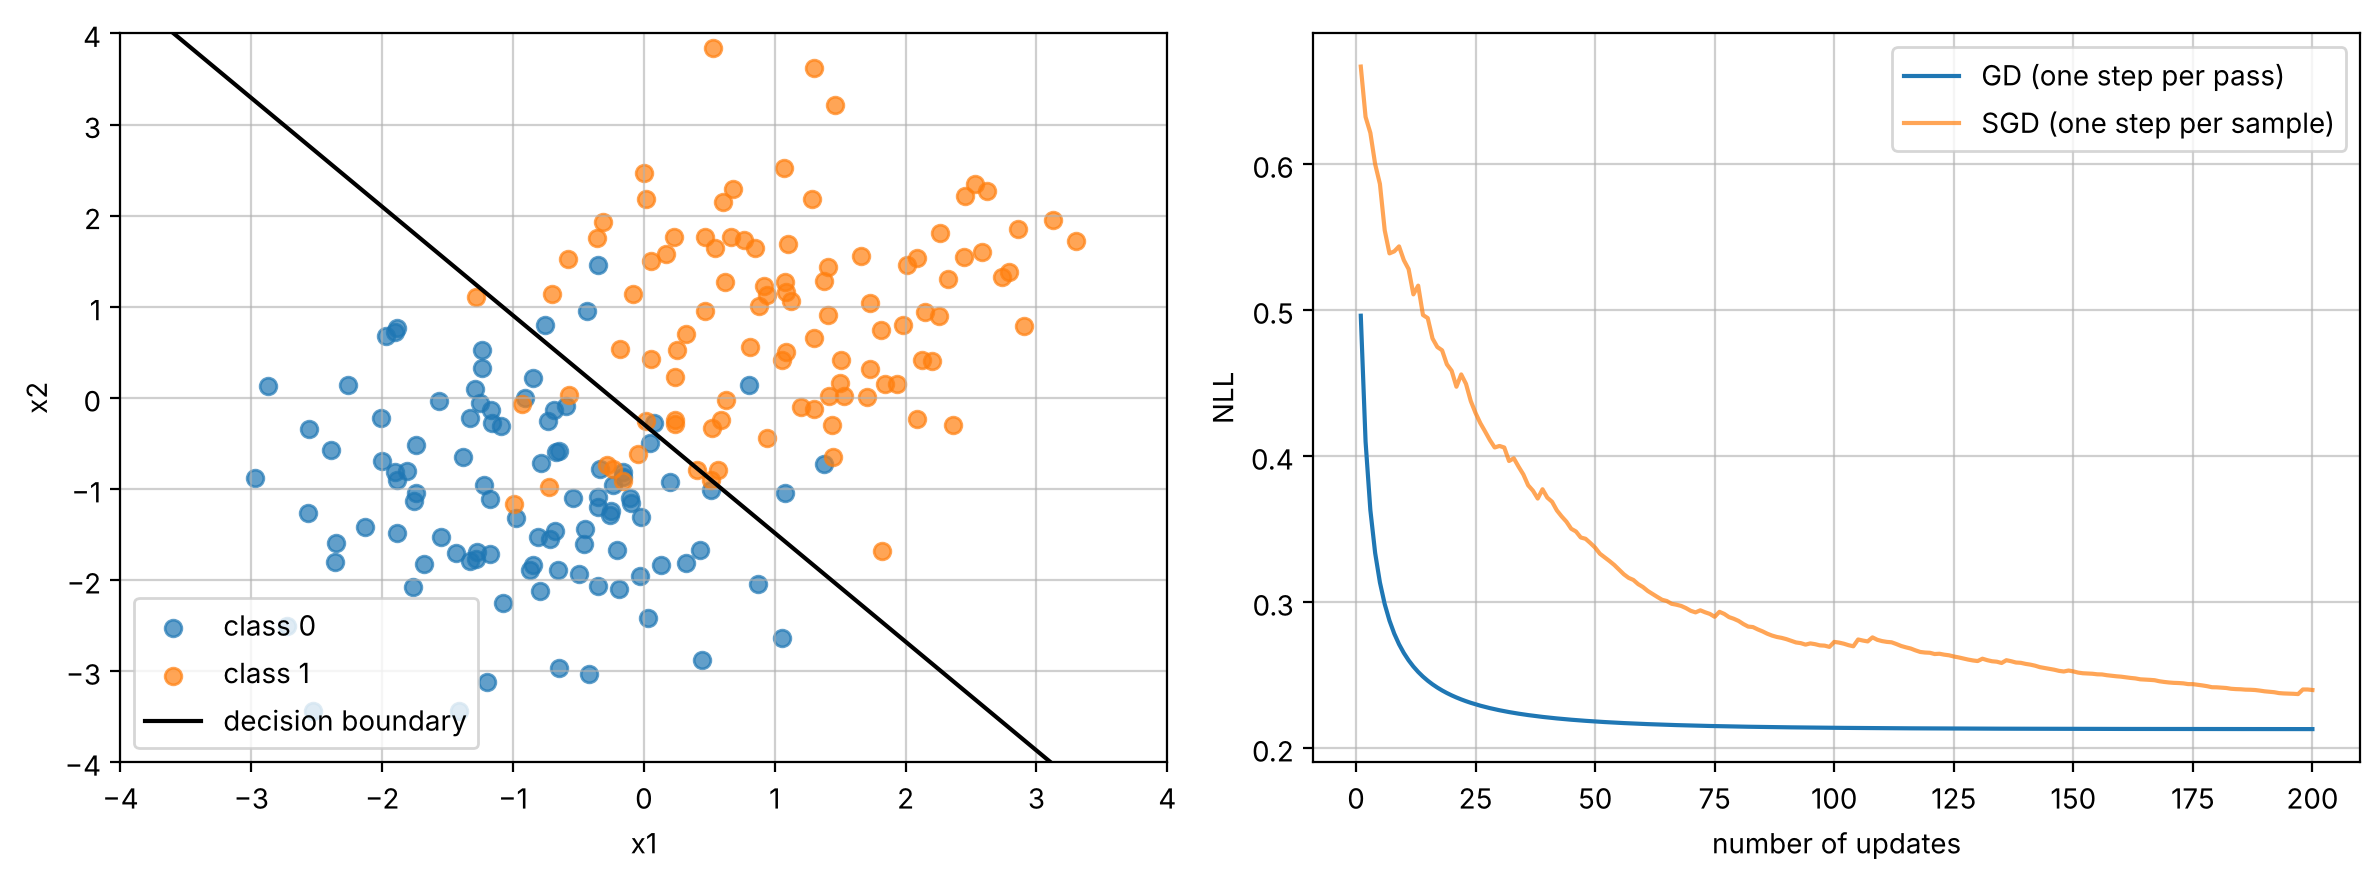

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# left: the data and the decision boundary w0 + w1 x1 + w2 x2 = 0
axes[0].scatter(X_raw[y == 0, 0], X_raw[y == 0, 1], label="class 0", alpha=0.7)
axes[0].scatter(X_raw[y == 1, 0], X_raw[y == 1, 1], label="class 1", alpha=0.7)
x1 = np.linspace(-4, 4, 100)
axes[0].plot(x1, -(w_gd[0] + w_gd[1]*x1) / w_gd[2], "k", label="decision boundary")
axes[0].set_xlim(-4, 4)
axes[0].set_ylim(-4, 4)
axes[0].set_xlabel("x1")
axes[0].set_ylabel("x2")
axes[0].legend()
axes[0].grid(True, alpha=0.6)

# right: the training loss, SGD has one update per sample so it is noisier
axes[1].plot(np.arange(1, len(hist_gd) + 1), hist_gd, label="GD (one step per pass)")
axes[1].plot(np.arange(1, len(hist_sgd) + 1), hist_sgd, label="SGD (one step per sample)", alpha=0.7)
axes[1].set_xlabel("number of updates")
axes[1].set_ylabel("NLL")
axes[1].legend()
axes[1].grid(True, alpha=0.6)
plt.tight_layout()

## 5.4 A Mind Experiment: Why the Gradient is so Important

Why not just try lots of values of $w$ and keep the best one? Because of the **Curse of Dimensionality**.

**Sampling Curse:** dense sampling becomes combinatorially impossible in high dimensions. If you want to place $k$ points per dimension to sample the space, you will need:
$$
\#\text{Total points} = k^d
$$
So for just $k = 10$ points per dimension with $d = 100$, you need $10^{100}$ samples! This is why naive brute-force or grid-based methods fail in ML and optimisation. The gradient tells us which direction to move in, with a cost that only grows linearly in $d$.

# 6. Worked Example: Maximum Likelihood by Hand

## 6.1 The Spam Filter

Consider a spam filter with one binary feature: $x = 1$ if the email contains "free", else $0$. The model is $p(\text{spam}|x) = \sigma(wx + b)$, trained on $N = 20$ emails:

| | spam ($y=1$) | not spam ($y=0$) |
|---|---|---|
| contains "free" ($x=1$) | 8 | 2 |
| no "free" ($x=0$) | 2 | 8 |

The predictions are $\sigma(w+b)$ for $x = 1$ and $\sigma(b)$ for $x = 0$. We set the gradient to zero:
$$
\begin{align*}
\frac{\partial\text{NLL}}{\partial w} &= \frac{1}{N}\sum_n(\mu_n - y_n)x_n = \frac{1}{20}\left[10\,\sigma(w+b) - 8\right] = 0 && (\text{only the 10 "free" emails have } x_n = 1) \\
\frac{\partial\text{NLL}}{\partial b} &= \frac{1}{N}\sum_n(\mu_n - y_n) = \frac{1}{20}\left[10\,\sigma(w+b) + 10\,\sigma(b) - 10\right] = 0 && (\text{all 20 emails, 10 of them spam})
\end{align*}
$$

## 6.2 What the Solution Tells Us

The first equation gives $\sigma(\hat{w}+\hat{b}) = 0.8$, and then the second gives $\sigma(\hat{b}) = 0.2$. We invert the sigmoid with the logit:
$$
\begin{align*}
\hat{b} &= \log\frac{0.2}{0.8} = -\log 4 \approx -1.39 \\
\hat{w} &= \log\frac{0.8}{0.2} - \hat{b} = \log 4 + \log 4 = \log 16 \approx 2.77
\end{align*}
$$
By convexity, this stationary point is the global minimum.
* **Fitted = observed:** $p(\text{spam}|x=1) = 0.8 = \frac{8}{10}$ and $p(\text{spam}|x=0) = 0.2 = \frac{2}{10}$.
* **Weight = log odds ratio:** $e^{\hat{w}} = \frac{0.8/0.2}{0.2/0.8} = 16$, so "free" multiplies the odds of spam by 16.

**In general:** with a bias, $\partial\text{NLL}/\partial b = 0$ gives $\sum_n\mu_n = \sum_ny_n$, so the average predicted probability equals the fraction of positives in the training set.

## 6.3 Checking the Solution in Python

In [9]:
# first we build the 20 emails from the table
x_free = np.array([1]*8 + [1]*2 + [0]*2 + [0]*8)
y_spam = np.array([1]*8 + [0]*2 + [1]*2 + [0]*8, dtype=float)
X_spam = add_bias(x_free)

# next we train with gradient descent
w_spam, _ = fit_logreg_gd(X_spam, y_spam, lr=2.0, n_iters=5000)
b_hat, w_hat = w_spam

print("--- Spam Filter MLE ---")
print(f"b_hat = {b_hat:.4f}   (by hand: -log 4 = {-np.log(4):.4f})")
print(f"w_hat = {w_hat:.4f}   (by hand:  log 16 = {np.log(16):.4f})")
print(f"p(spam | free)    = {sigmoid(w_hat + b_hat):.3f}")
print(f"p(spam | no free) = {sigmoid(b_hat):.3f}")
print(f"odds ratio e^w    = {np.exp(w_hat):.2f}")
print(f"mean prediction = {sigmoid(X_spam @ w_spam).mean():.3f}, fraction spam = {y_spam.mean():.3f}")

--- Spam Filter MLE ---
b_hat = -1.3863   (by hand: -log 4 = -1.3863)
w_hat = 2.7726   (by hand:  log 16 = 2.7726)
p(spam | free)    = 0.800
p(spam | no free) = 0.200
odds ratio e^w    = 16.00
mean prediction = 0.500, fraction spam = 0.500


# 7. Separable vs. Non-Separable Data

## 7.1 Solution Behaviour

The optimal solution for the weights $w$ behaves very differently depending on the data.

### Case 1: Non-Linearly Separable Data
* When classes overlap, no hyperplane can perfectly separate them.
* The model must find a compromise. The MLE is a finite set of weights $w$ (unique unless features are collinear).
* This solution defines the decision boundary that best separates the data, balancing the misclassification errors to minimise the overall cross-entropy loss.

### Case 2: Linearly Separable Data
* If a hyperplane can perfectly separate the data, a problem arises.
* To maximise the likelihood, the model tries to make its predictions perfectly confident (probabilities of $0$ or $1$).
* This requires the logits $w^Tx$ to go to $\pm\infty$. The optimisation algorithm will keep increasing the magnitude of $w$, and the weights will grow infinitely large.
* **Solution:** use regularization (e.g. L2) to add a penalty for large weights, ensuring a stable, finite solution.

## 7.2 Worked Example, Part 2: A Perfect Predictor

Now suppose all 10 "free" emails are spam (the $x = 0$ row is unchanged). Only these emails involve $w$, each with $y = 1$:
$$
\frac{\partial\text{NLL}}{\partial w} = \frac{1}{20}\left[10\,\sigma(w+b) - 10\right] = \frac{1}{2}\left[\sigma(w+b) - 1\right] < 0 \quad \text{for all finite } w,b
$$
The loss keeps falling as $w$ grows, so there is no finite MLE, even though the data are not separable overall.

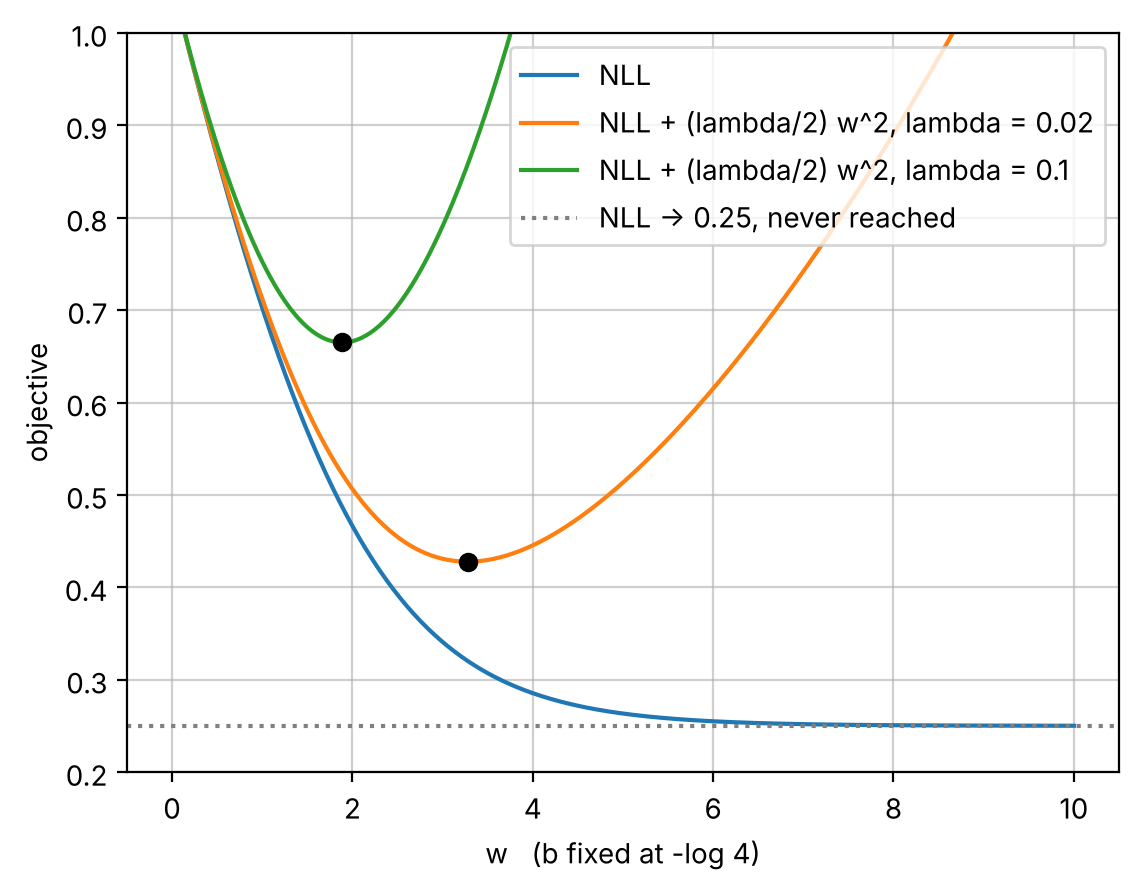

In [10]:
# the NLL as a function of w, with b fixed at -log 4
b_fix = -np.log(4)
w_grid = np.linspace(0, 10, 400)

def nll_perfect(w, b):
    # 10 "free" emails all spam, 2 spam + 8 not spam without "free"
    return (10*-np.log(sigmoid(w + b)) + 2*-np.log(sigmoid(b)) + 8*-np.log(1 - sigmoid(b))) / 20

plt.plot(w_grid, nll_perfect(w_grid, b_fix), label="NLL")
for lam in [0.02, 0.1]:
    J = nll_perfect(w_grid, b_fix) + lam/2*w_grid**2
    plt.plot(w_grid, J, label=f"NLL + (lambda/2) w^2, lambda = {lam}")
    plt.plot(w_grid[np.argmin(J)], J.min(), "ko")

limit = nll_perfect(np.inf, b_fix)
plt.axhline(limit, color="gray", linestyle=":", label=f"NLL -> {limit:.2f}, never reached")
plt.xlabel("w   (b fixed at -log 4)")
plt.ylabel("objective")
plt.ylim(0.2, 1)
plt.legend()
plt.grid(True, alpha=0.6)

## 7.3 L2 Regularization Restores a Unique, Finite Solution

We now minimise:
$$
J(w) = \text{NLL}(w) + \frac{\lambda}{2}\|w\|^2, \quad \lambda > 0
$$
(with the bias absorbed into $w$).

### Theorem
For any $\lambda > 0$, $J(w)$ has exactly one minimiser.

### Proof
* **At most one minimiser:** $\nabla_w^2J = H(w) + \lambda I \succeq \lambda I \succ 0$, since $H(w) \succeq 0$ (Section 4.7). So $J$ is strictly convex.
* **A minimiser exists:** $J(w) \geq \frac{\lambda}{2}\|w\|^2 \to \infty$ as $\|w\| \to \infty$ (since $\text{NLL} \geq 0$), so $J$ can't keep decreasing forever.

### Back to the perfect predictor
Setting the derivative w.r.t. $w$ to zero:
$$
\begin{align*}
\frac{\partial J}{\partial w} = \frac{1}{2}\left[\sigma(w+b) - 1\right] + \lambda w &= 0 \\
\implies \lambda\hat{w}_\lambda &= \frac{1}{2}\left[1 - \sigma(\hat{w}_\lambda + \hat{b}_\lambda)\right] \in \left(0,\tfrac{1}{2}\right)
\end{align*}
$$
So $0 < \hat{w}_\lambda < \frac{1}{2\lambda}$, which shrinks as $\lambda$ grows.

**Note:** just like ridge regression in Week 2, L2 is MAP estimation with the prior $w \sim \mathcal{N}\left(0, \frac{1}{\lambda N}I\right)$. Multiplying $J$ by $N$ gives $-\log p(D|w) + \frac{\lambda N}{2}\|w\|^2$, and the second term is $-\log p(w)$ for that Gaussian, up to a constant.

## 7.4 Exploding Weights in Python

We can see Case 2 happen by training on two clouds of points that are far apart (so they are linearly separable), with and without L2 regularization.

No regularization : ||w|| = 4.73 and still growing, accuracy = 1.00
L2, lambda = 0.01 : ||w|| = 1.87 (converged),   accuracy = 1.00


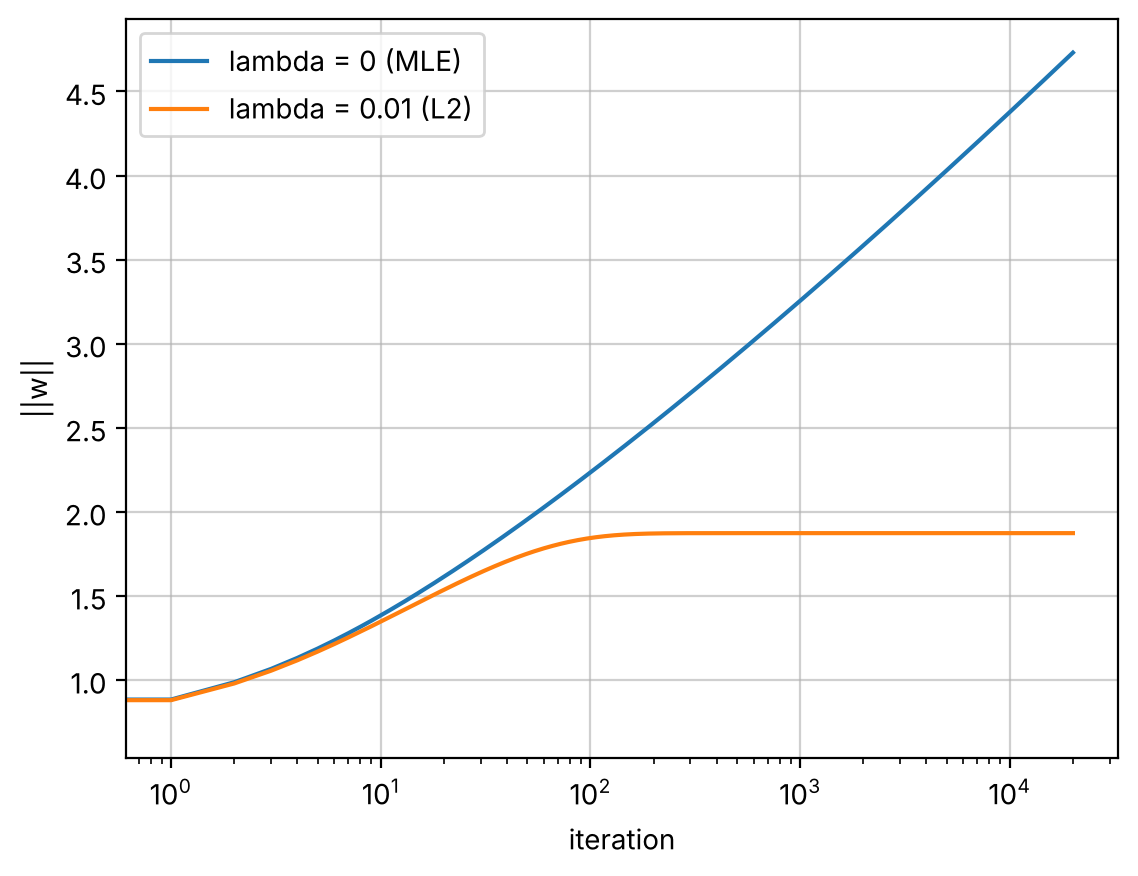

In [11]:
rng = np.random.default_rng(3)

# first we create linearly separable data
N = 100
X_sep_raw = np.vstack([rng.normal([-2, -2], 0.7, size=(N//2, 2)),
                       rng.normal([ 2,  2], 0.7, size=(N//2, 2))])
y_sep = np.concatenate([np.zeros(N//2), np.ones(N//2)])
X_sep = add_bias(X_sep_raw)

# next we train with and without L2, tracking the size of the weights as we go
def weight_norm_path(lam, n_iters=20000, lr=0.5):
    w = np.zeros(3)
    norms = []
    for t in range(n_iters):
        w = w - lr*(X_sep.T @ (sigmoid(X_sep @ w) - y_sep) / N + lam*w)
        norms.append(np.linalg.norm(w))
    return w, np.array(norms)

w_mle, norms_mle = weight_norm_path(lam=0.0)
w_l2,  norms_l2  = weight_norm_path(lam=0.01)

print(f"No regularization : ||w|| = {norms_mle[-1]:.2f} and still growing, accuracy = {np.mean(predict(X_sep, w_mle) == y_sep):.2f}")
print(f"L2, lambda = 0.01 : ||w|| = {norms_l2[-1]:.2f} (converged),   accuracy = {np.mean(predict(X_sep, w_l2) == y_sep):.2f}")

plt.plot(norms_mle, label="lambda = 0 (MLE)")
plt.plot(norms_l2, label="lambda = 0.01 (L2)")
plt.xscale("log")
plt.xlabel("iteration")
plt.ylabel("||w||")
plt.legend()
plt.grid(True, alpha=0.6)

Both models get 100% training accuracy, but without regularization $\|w\|$ keeps growing (roughly like $\log t$) forever, while the L2 model settles at a finite value.

# 8. Handling Nonlinearity

## 8.1 Feature Transformations

What if the data is not linearly separable?
* We can create nonlinear classifiers by transforming the input features.
* We replace the input $x$ with a new feature vector $\phi(x)$.
* The model is still linear with respect to the new features (a.k.a. **Generalized Linear Models**), so everything above still works.

**Example: Quadratic Boundary.** If we transform $x = (x_1,x_2)$ to $\phi(x) = (x_1^2,x_2^2)$, a linear boundary in the new space $w_1x_1^2 + w_2x_2^2 + b = 0$ corresponds to a circular or elliptical boundary in the original space.

Accuracy with x = (x1, x2)         : 0.730
Accuracy with phi(x) = (x1^2, x2^2): 0.993


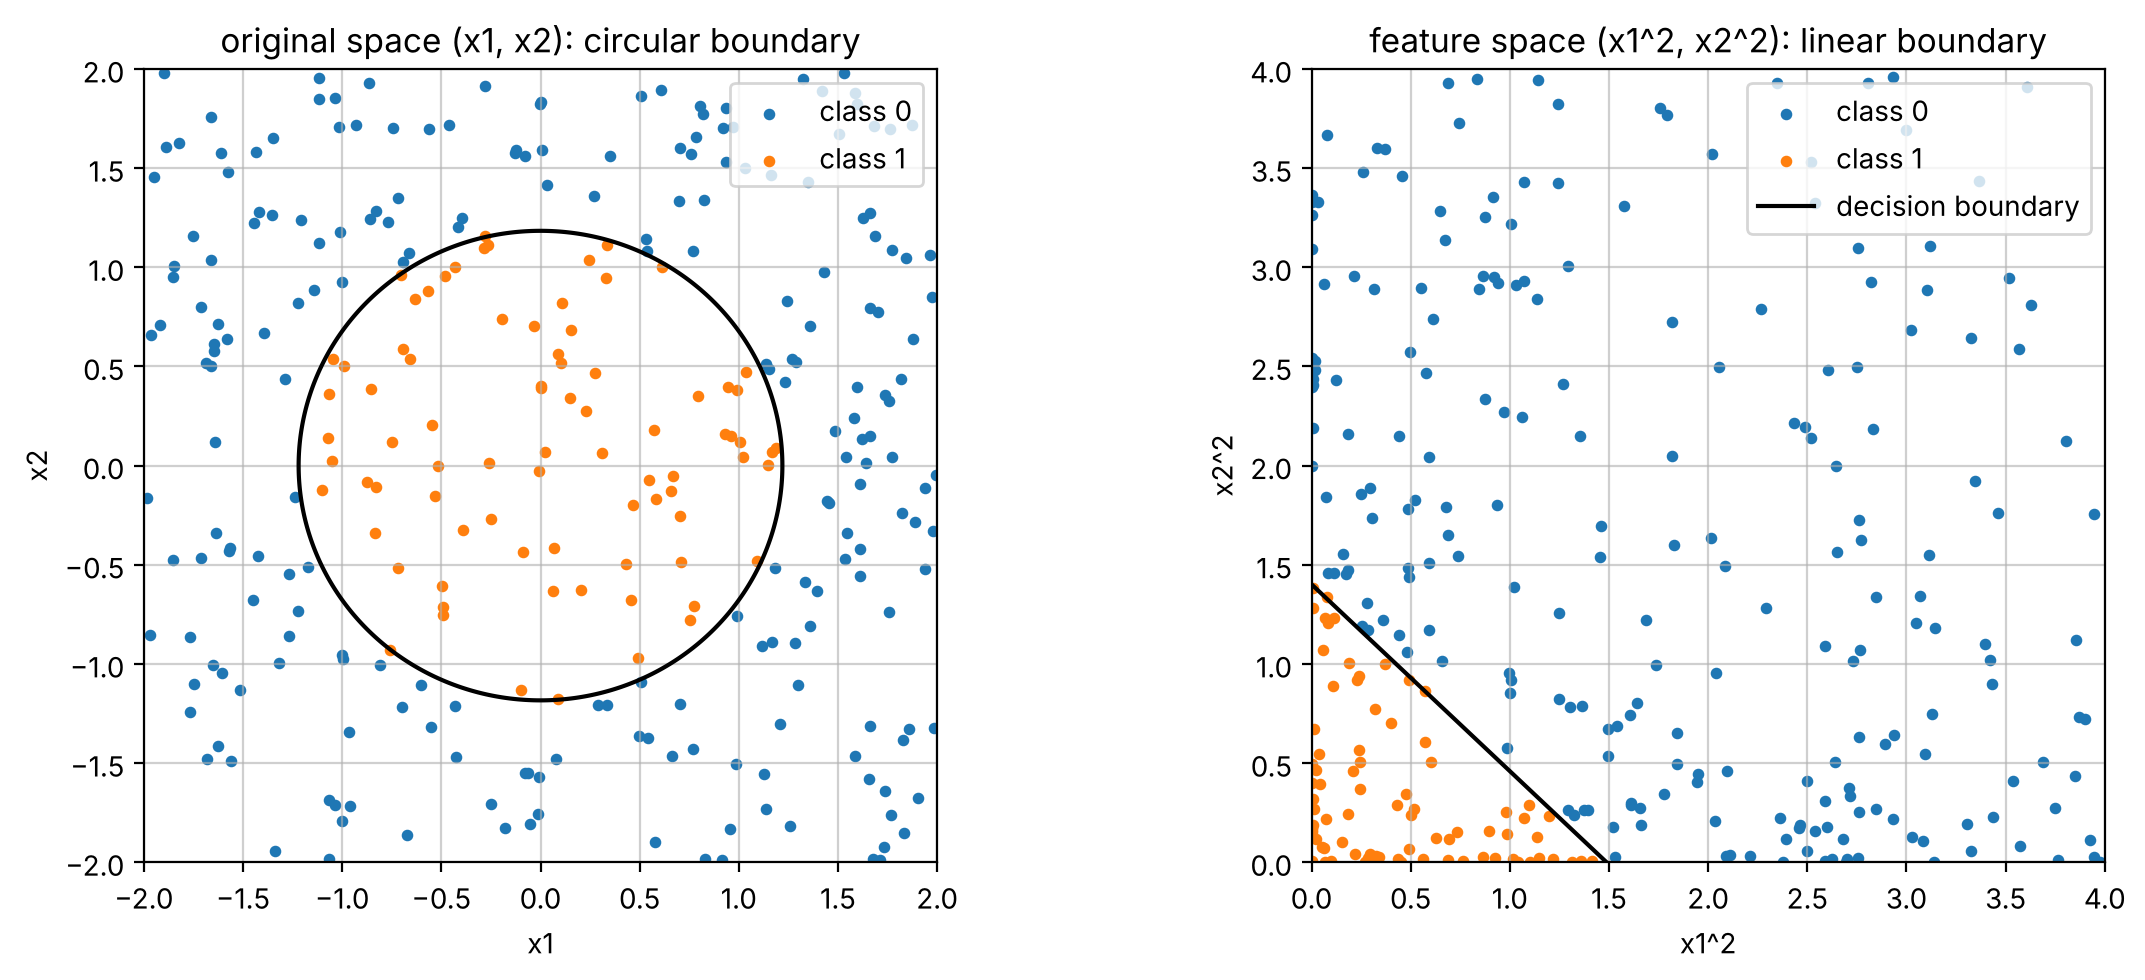

In [12]:
rng = np.random.default_rng(4)

# first we create data where class 1 is inside a circle of radius 1.2
N = 300
X_circ = rng.uniform(-2, 2, size=(N, 2))
y_circ = (X_circ[:, 0]**2 + X_circ[:, 1]**2 < 1.2**2).astype(float)

# model 1: linear features x = (x1, x2)
w_lin, _ = fit_logreg_gd(add_bias(X_circ), y_circ, lr=0.5, n_iters=3000)

# model 2: quadratic features phi(x) = (x1^2, x2^2)
phi = lambda X: X**2
w_quad, _ = fit_logreg_gd(add_bias(phi(X_circ)), y_circ, lr=0.5, n_iters=3000, lam=1e-3)

print(f"Accuracy with x = (x1, x2)         : {np.mean(predict(add_bias(X_circ), w_lin) == y_circ):.3f}")
print(f"Accuracy with phi(x) = (x1^2, x2^2): {np.mean(predict(add_bias(phi(X_circ)), w_quad) == y_circ):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
# left: original space, the boundary is a circle
g1, g2 = np.meshgrid(np.linspace(-2, 2, 300), np.linspace(-2, 2, 300))
grid = np.column_stack([g1.ravel(), g2.ravel()])
p_grid = sigmoid(add_bias(phi(grid)) @ w_quad).reshape(g1.shape)
axes[0].scatter(X_circ[y_circ == 0, 0], X_circ[y_circ == 0, 1], s=10, label="class 0")
axes[0].scatter(X_circ[y_circ == 1, 0], X_circ[y_circ == 1, 1], s=10, label="class 1")
axes[0].contour(g1, g2, p_grid, levels=[0.5], colors="black")
axes[0].set_title("original space (x1, x2): circular boundary")
axes[0].set_xlabel("x1")
axes[0].set_ylabel("x2")

# right: feature space, the same boundary is a straight line
Z = phi(X_circ)
axes[1].scatter(Z[y_circ == 0, 0], Z[y_circ == 0, 1], s=10, label="class 0")
axes[1].scatter(Z[y_circ == 1, 0], Z[y_circ == 1, 1], s=10, label="class 1")
z1 = np.linspace(0, 4, 100)
axes[1].plot(z1, -(w_quad[0] + w_quad[1]*z1) / w_quad[2], "k", label="decision boundary")
axes[1].set_xlim(0, 4)
axes[1].set_ylim(0, 4)
axes[1].set_title("feature space (x1^2, x2^2): linear boundary")
axes[1].set_xlabel("x1^2")
axes[1].set_ylabel("x2^2")
for ax in axes:
    ax.set_aspect("equal")
    ax.legend(loc="upper right")
    ax.grid(True, alpha=0.6)
plt.tight_layout()

## 8.2 The Problem of Overfitting

Using complex features (e.g. high-degree polynomials) can make the model too flexible, and regularization can be used to mitigate this.
* The model may learn the training data perfectly but fail to generalise to new, unseen test data.
* This often happens when the model parameters (weights) take on very large values to "wiggle" the decision boundary around individual data points.

To see this, we expand $x = (x_1,x_2)$ into all monomials $x_1^ix_2^j$ with $i + j \leq K$, and fit with increasing degree $K$.

Note: for this demo we use **Newton's method**, $w_{t+1} = w_t - H^{-1}\nabla_wJ$, which uses the Hessian from Section 4.6 and converges in far fewer steps than gradient descent. A tiny L2 penalty keeps the Hessian invertible, and we halve the step whenever it would make the loss go up.

In [13]:
def poly_features_2d(X, K):
    # all monomials x1^i x2^j with 1 <= i + j <= K (the bias is added separately)
    cols = [X[:, 0]**i * X[:, 1]**(d - i) for d in range(1, K + 1) for i in range(d + 1)]
    return np.column_stack(cols)

def reg_nll(w, X, y, lam):
    # NLL + (lam/2)||w||^2, using log(1 + e^a) - y a which is the same NLL written so it never takes log(0)
    a = X @ w
    return np.mean(np.logaddexp(0, a) - y*a) + lam/2*(w @ w)

def fit_logreg_newton(X, y, lam=1e-6, n_iters=100):
    # Newton's method on NLL(w) + (lam/2)||w||^2
    w = np.zeros(X.shape[1])
    for t in range(n_iters):
        mu = sigmoid(X @ w)
        grad = X.T @ (mu - y) / len(y) + lam*w
        H = (X.T * (mu*(1 - mu))) @ X / len(y) + lam*np.eye(len(w))
        step = np.linalg.solve(H, grad)
        # halve the step until the objective goes down (keeps Newton stable)
        s = 1.0
        while reg_nll(w - s*step, X, y, lam) > reg_nll(w, X, y, lam) and s > 1e-10:
            s /= 2
        w = w - s*step
    return w

rng = np.random.default_rng(2)

def make_moons_ish(n):
    # a curved boundary x2 = sin(2.5 x1) with 10% of the labels flipped as noise
    X = rng.uniform(-1.5, 1.5, size=(n, 2))
    y = (X[:, 1] > np.sin(2.5*X[:, 0])).astype(float)
    flip = rng.random(n) < 0.10
    y[flip] = 1 - y[flip]
    return X, y

X_tr, y_tr = make_moons_ish(50)
X_te, y_te = make_moons_ish(2000)

degrees = range(1, 11)
train_err, test_err, models = [], [], {}
for K in degrees:
    w = fit_logreg_newton(add_bias(poly_features_2d(X_tr, K)), y_tr)
    models[K] = w
    train_err.append(np.mean(predict(add_bias(poly_features_2d(X_tr, K)), w) != y_tr))
    test_err.append(np.mean(predict(add_bias(poly_features_2d(X_te, K)), w) != y_te))

print(f"{'K':<4} {'#params':<9} {'train err':<11} {'test err':<10} {'max |w|':<10}")
print("-" * 46)
for K in degrees:
    print(f"{K:<4} {len(models[K]):<9} {train_err[K-1]:<11.3f} {test_err[K-1]:<10.3f} {np.max(np.abs(models[K])):<10.1e}")

K    #params   train err   test err   max |w|   
----------------------------------------------
1    3         0.140       0.230      3.0e+00   
2    6         0.160       0.228      3.2e+00   
3    10        0.120       0.172      1.1e+01   
4    15        0.040       0.287      4.9e+01   
5    21        0.000       0.299      8.6e+01   
6    28        0.000       0.298      9.0e+01   
7    36        0.000       0.293      9.0e+01   
8    45        0.000       0.298      8.6e+01   
9    55        0.000       0.301      8.5e+01   
10   66        0.000       0.306      8.1e+01   


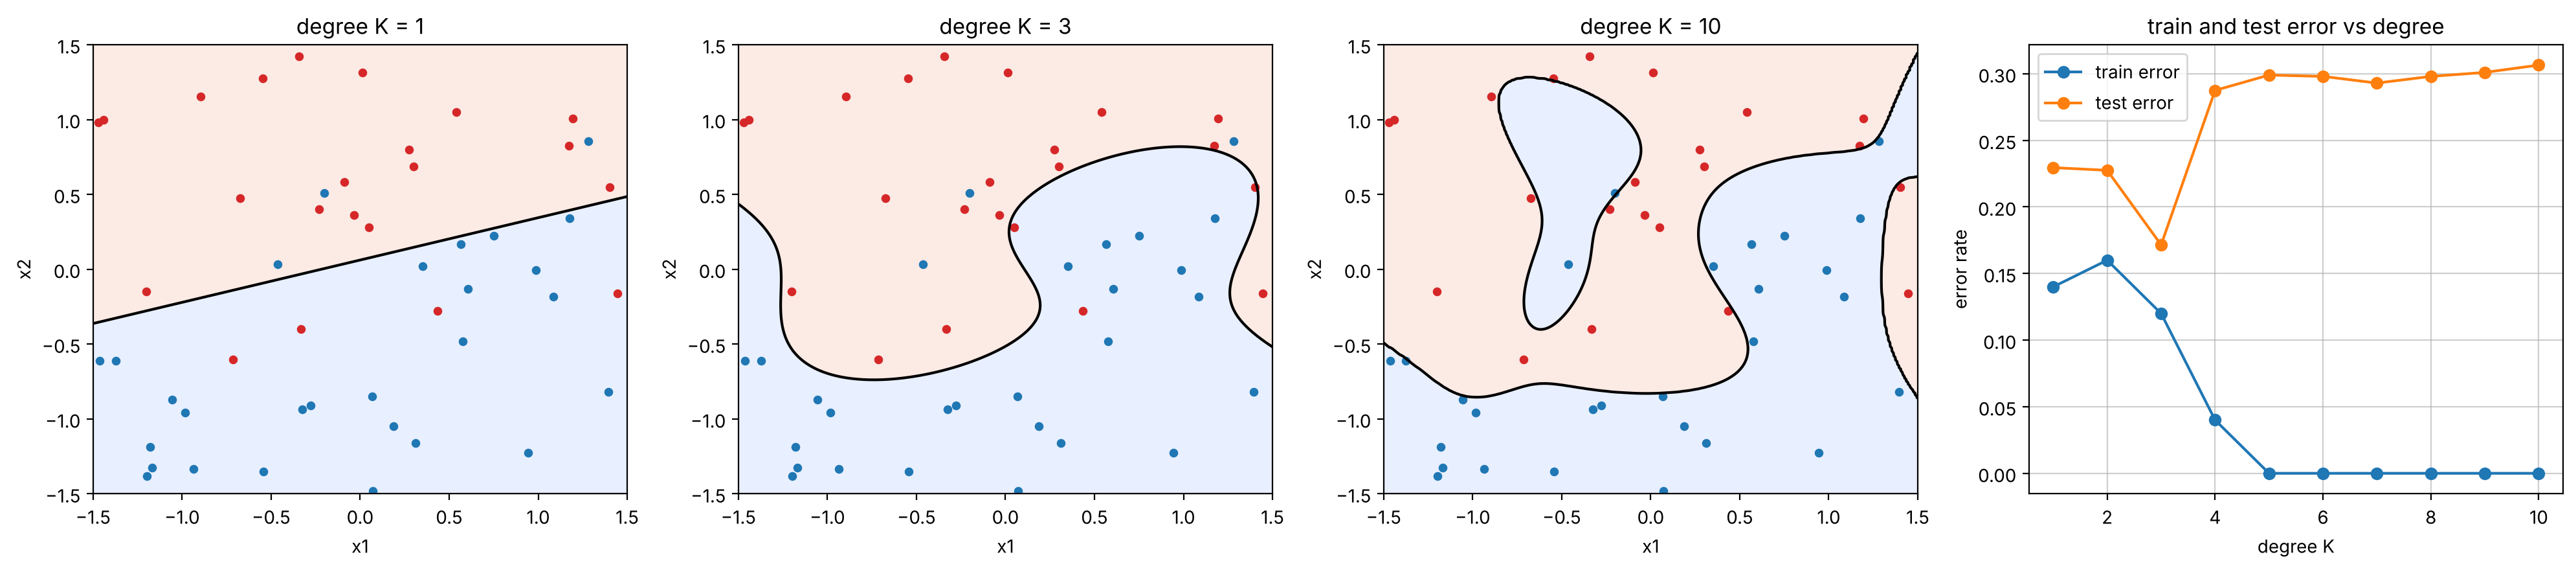

In [14]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
g1, g2 = np.meshgrid(np.linspace(-1.5, 1.5, 300), np.linspace(-1.5, 1.5, 300))
grid = np.column_stack([g1.ravel(), g2.ravel()])

for ax, K in zip(axes[:3], [1, 3, 10]):
    p = sigmoid(add_bias(poly_features_2d(grid, K)) @ models[K]).reshape(g1.shape)
    ax.contourf(g1, g2, p >= 0.5, alpha=0.2, cmap="coolwarm")
    ax.contour(g1, g2, p, levels=[0.5], colors="black")
    ax.scatter(X_tr[y_tr == 0, 0], X_tr[y_tr == 0, 1], c="tab:blue", s=15)
    ax.scatter(X_tr[y_tr == 1, 0], X_tr[y_tr == 1, 1], c="tab:red", s=15)
    ax.set_title(f"degree K = {K}")
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")

axes[3].plot(degrees, train_err, "o-", label="train error")
axes[3].plot(degrees, test_err, "o-", label="test error")
axes[3].set_xlabel("degree K")
axes[3].set_ylabel("error rate")
axes[3].set_title("train and test error vs degree")
axes[3].legend()
axes[3].grid(True, alpha=0.6)
plt.tight_layout()

As the model complexity (polynomial degree) increases, the training error drops but the test error starts to rise, which indicates overfitting.

# 9. Multinomial Logistic Regression

## 9.1 The Softmax Function

How do we handle more than two classes? The sigmoid function only outputs a single probability for class 1. So we need a function that can output a probability distribution over all $C$ classes, and this function is the **softmax function**.

For a vector of logits $a = [a_1,\dots,a_C]$, the probability of class $c$ is:
$$
p(y = c|x,\theta) = \text{softmax}(a)_c = \frac{e^{a_c}}{\sum_{c'=1}^{C}e^{a_{c'}}}
$$
The logits for each class are computed with a separate weight vector: $a_c = w_c^Tx$.
* The outputs are all positive and sum to 1, forming a valid probability distribution.
* The model is now defined by a weight matrix $W$ (where each row is a $w_c^T$) and a bias vector $b$.

Note: with $C = 2$, $\text{softmax}(a)_1 = \frac{e^{a_1}}{e^{a_0} + e^{a_1}} = \frac{1}{1 + e^{-(a_1 - a_0)}} = \sigma(a_1 - a_0)$, so we get binary logistic regression back.

## 9.2 The Gradient for Softmax Regression

We write the label as a one-hot vector $y = (y_1,\dots,y_C)$, so the NLL for one point is the **cross-entropy**:
$$
J = -\sum_{c=1}^{C}y_c\log\mu_c, \quad \mu_c = \text{softmax}(a)_c
$$
The derivative of the log-softmax is $\frac{\partial\log\mu_c}{\partial a_k} = \mathbb{1}[c = k] - \mu_k$. So:
$$
\begin{align*}
\frac{\partial J}{\partial a_k} &= -\sum_{c=1}^{C}y_c\left(\mathbb{1}[c=k] - \mu_k\right) \\
&= -y_k + \mu_k\sum_{c=1}^{C}y_c && (\text{only } c = k \text{ survives in the first term}) \\
&= \mu_k - y_k && (\text{since } \textstyle\sum_cy_c = 1)
\end{align*}
$$
And since $\nabla_{w_k}a_k = x$, we get the same form as before:
$$
\nabla_{w_k}J = (\mu_k - y_k)x = (\text{prediction} - \text{actual}) \times \text{input}
$$

## 9.3 Softmax Regression in Python

In [15]:
def softmax(A):
    # subtract the row max before exponentiating, for numerical stability (doesn't change the result)
    A = A - A.max(axis=1, keepdims=True)
    E = np.exp(A)
    return E / E.sum(axis=1, keepdims=True)

def fit_softmax_gd(X, y, C, lr=0.5, n_iters=2000, lam=0.0):
    # W has one row per class, X already contains the bias column
    N, D = X.shape
    Y = np.eye(C)[y]                    # one-hot labels, N x C
    W = np.zeros((C, D))
    for t in range(n_iters):
        M = softmax(X @ W.T)            # predictions mu, N x C
        grad = (M - Y).T @ X / N + lam*W
        W = W - lr*grad
    return W

rng = np.random.default_rng(6)

# first we create 3 classes, e.g. cat / dog / bird
centres = np.array([[-2, 0], [2, 0], [0, 2.5]])
X3_raw = np.vstack([rng.normal(c, 0.9, size=(80, 2)) for c in centres])
y3 = np.repeat([0, 1, 2], 80)
X3 = add_bias(X3_raw)

# next we fit the model and predict the most probable class
W3 = fit_softmax_gd(X3, y3, C=3)
pred3 = np.argmax(softmax(X3 @ W3.T), axis=1)
print(f"Training accuracy (3 classes): {np.mean(pred3 == y3):.3f}")
print(f"Probabilities for the first point: {np.round(softmax(X3[:1] @ W3.T)[0], 3)} (sum = {softmax(X3[:1] @ W3.T).sum():.1f})")

Training accuracy (3 classes): 0.958
Probabilities for the first point: [0.178 0.    0.822] (sum = 1.0)


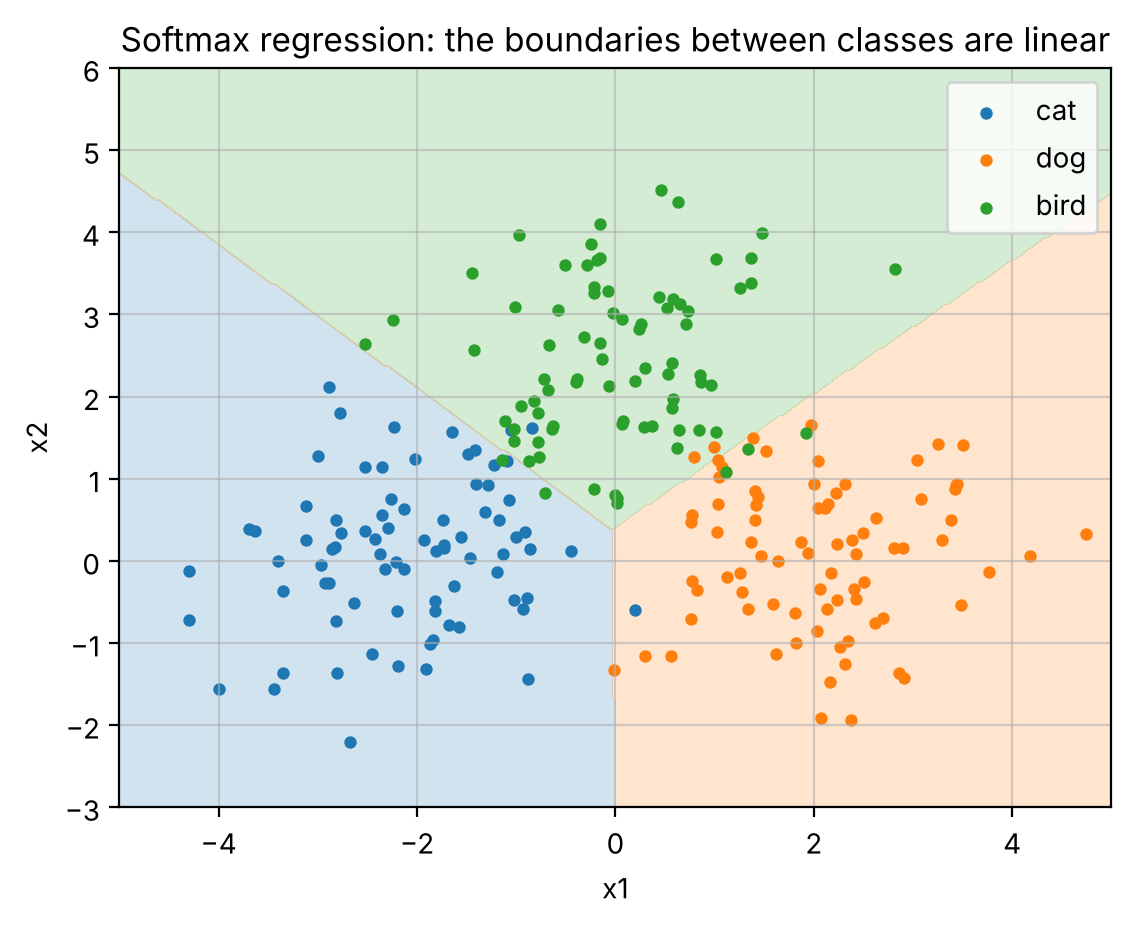

In [16]:
g1, g2 = np.meshgrid(np.linspace(-5, 5, 300), np.linspace(-3, 6, 300))
grid = add_bias(np.column_stack([g1.ravel(), g2.ravel()]))
regions = np.argmax(softmax(grid @ W3.T), axis=1).reshape(g1.shape)

plt.contourf(g1, g2, regions, alpha=0.2, levels=[-0.5, 0.5, 1.5, 2.5], colors=["tab:blue", "tab:orange", "tab:green"])
for c, name in enumerate(["cat", "dog", "bird"]):
    plt.scatter(X3_raw[y3 == c, 0], X3_raw[y3 == c, 1], s=12, label=name)
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Softmax regression: the boundaries between classes are linear")
plt.legend()
plt.grid(True, alpha=0.6)

# 10. Naive Bayes Classifier

## 10.1 Generative vs. Discriminative

A different approach to classification is to model the data itself.
* **Discriminative Models** (e.g. Logistic Regression) model the decision boundary directly, $p(y|x)$. They answer: "Given these features, what is the probability of this class?"
* **Generative Models** (e.g. Naive Bayes) model how the data for each class is generated, $p(x,y) = p(x|y)p(y)$. They answer: "Given this class, what is the probability of seeing these features?"

For a generative model, we can then use Bayes' rule to get the posterior probability $p(y|x)$ we need for classification.

## 10.2 The Naive Bayes Assumption

The core of the Naive Bayes Classifier is a very strong, or "naive", assumption.

### The Assumption: Conditional Independence
It assumes that all features $x_d$ are **conditionally independent** of each other, given the class label $y$.

What this means is that knowing the value of one feature tells you nothing new about another feature, as long as you already know the class.
* **Example:** for a "spam" email, the probability of seeing the word "viagra" is independent of the probability of seeing "free".
* This is rarely true in reality, but the model often works surprisingly well anyway!

## 10.3 The Naive Bayes Model

Because of the conditional independence assumption, we can write the class-conditional density $p(x|y=c)$ as a product of individual feature probabilities:
$$
p(x|y=c,\theta) = \prod_{d=1}^{D}p(x_d|y=c,\theta_{dc})
$$
Using Bayes' rule, the posterior probability for class $c$ is:
$$
p(y=c|x,\theta) = \frac{p(y=c|\pi)\prod_{d=1}^{D}p(x_d|y=c,\theta_{dc})}{\sum_{c'}p(y=c'|\pi)\prod_{d=1}^{D}p(x_d|y=c',\theta_{dc'})}
$$
Where:
$$\begin{align}
    &p(y=c|\pi) = \pi_c \text{: is the class prior (overall probability of class } c\text{)} \\
    &p(x_d|y=c,\theta_{dc}) \text{: is the class-conditional likelihood for feature } d \\
    &\text{the denominator} \text{: is the same for every class, it just makes the posteriors sum to 1}
\end{align}
$$

## 10.4 Fitting a Naive Bayes Classifier

Fitting (training) a Naive Bayes model is extremely simple and efficient, because the parameters can be estimated separately.

**Class Priors ($\pi_c$):** the MLE is simply the frequency of each class in the training data:
$$
\hat{\pi}_c = \frac{N_c}{N} = \frac{\text{count of class } c}{\text{total count}}
$$
**For Binary Features (Bernoulli Naive Bayes):**
$$
\hat{\theta}_{dc} = \frac{N_{dc}}{N_c} = \frac{\text{count of feature } d \text{ being on in class } c}{\text{count of class } c}
$$
**For Real-Valued Features (Gaussian Naive Bayes):** we calculate the sample mean and variance of feature $d$ for all data points belonging to class $c$:
$$
\hat{\mu}_{dc} = \frac{1}{N_c}\sum_{n:y_n=c}x_{nd}, \qquad \hat{\sigma}^2_{dc} = \frac{1}{N_c}\sum_{n:y_n=c}(x_{nd} - \hat{\mu}_{dc})^2
$$
These are exactly the Bernoulli and Gaussian MLEs from Week 2, just computed separately for each class and each feature.

## 10.5 Gaussian Naive Bayes in Python

In [17]:
class GaussianNaiveBayes:
    # a generative classifier, fitting is just counting, means and variances
    def fit(self, X, y):
        self.classes = np.unique(y)
        self.prior = np.array([np.mean(y == c) for c in self.classes])             # pi_c = N_c / N
        self.mu    = np.array([X[y == c].mean(axis=0) for c in self.classes])      # mu_dc
        self.var   = np.array([X[y == c].var(axis=0) for c in self.classes])       # sigma^2_dc (divide by N_c)
        return self

    def predict_proba(self, X):
        # log p(y=c) + sum_d log N(x_d | mu_dc, sigma^2_dc), computed in logs to avoid underflow
        log_lik = -0.5*(np.log(2*np.pi*self.var)[None, :, :]
                        + (X[:, None, :] - self.mu[None, :, :])**2 / self.var[None, :, :]).sum(axis=2)
        log_post = np.log(self.prior)[None, :] + log_lik
        return softmax(log_post)      # normalising = dividing by the denominator in Bayes' rule

    def predict(self, X):
        return self.classes[np.argmax(self.predict_proba(X), axis=1)]

# we use the same 3-class data as Section 9.3
nb = GaussianNaiveBayes().fit(X3_raw, y3)
print("--- Gaussian Naive Bayes ---")
print(f"Class priors pi_c : {np.round(nb.prior, 3)}")
print(f"Class means mu_dc :\n{np.round(nb.mu, 3)}")
print(f"Training accuracy -> Naive Bayes: {np.mean(nb.predict(X3_raw) == y3):.3f}, Softmax regression: {np.mean(pred3 == y3):.3f}")

--- Gaussian Naive Bayes ---
Class priors pi_c : [0.333 0.333 0.333]
Class means mu_dc :
[[-2.106  0.099]
 [ 2.047  0.071]
 [ 0.014  2.441]]
Training accuracy -> Naive Bayes: 0.958, Softmax regression: 0.958


## 10.6 Generative vs. Discriminative Classifiers

**Generative (e.g. Naive Bayes)**

Pros:
* Very fast to fit (often just counting).
* Can easily handle missing features.
* Can work with unlabelled data (semi-supervised).

Cons:
* Strong independence assumptions may not hold.
* Can have lower predictive accuracy.

**Discriminative (e.g. Logistic Regression)**

Pros:
* Often higher predictive accuracy.
* Doesn't need to model the feature distribution $p(x)$.
* Can easily handle arbitrary feature preprocessing.

Cons:
* Slower to train (requires optimisation).
* Harder to handle missing features.

# 11. Evaluating Classification Models

## 11.1 Why Accuracy Can Be Misleading

Accuracy is the most intuitive metric:
$$
\text{Accuracy} = \frac{\text{Number of correct predictions}}{\text{Total number of predictions}}
$$
**The Problem with Imbalanced Data:** consider a dataset for detecting a rare disease, where 99% of patients are healthy (Negative class) and 1% are sick (Positive class). A trivial model that always predicts "healthy" would achieve 99% accuracy!

However, this model is completely useless, as it never identifies a single sick patient. So we need more nuanced metrics.

In [18]:
rng = np.random.default_rng(7)

# first we simulate 10,000 patients, 1% are sick, and one test score that is higher for sick patients
N = 10000
y_dis = (rng.random(N) < 0.01).astype(int)
score = rng.normal(0, 1, N) + 2.5*y_dis
X_dis = add_bias(score)

# next we compare a trivial "always healthy" model with logistic regression
pred_trivial = np.zeros(N, dtype=int)
w_dis, _ = fit_logreg_gd(X_dis, y_dis.astype(float), lr=1.0, n_iters=3000)
p_dis = sigmoid(X_dis @ w_dis)

print(f"Fraction sick                   : {y_dis.mean():.3f}")
print(f"Accuracy of 'always healthy'    : {np.mean(pred_trivial == y_dis):.3f}")
print(f"Sick patients found by trivial  : {np.sum((pred_trivial == 1) & (y_dis == 1))} out of {y_dis.sum()}")

Fraction sick                   : 0.010
Accuracy of 'always healthy'    : 0.990
Sick patients found by trivial  : 0 out of 98


## 11.2 The Confusion Matrix

A **confusion matrix** is a table that visualises the performance of a classifier by breaking down the predictions for a given decision threshold.

| | Predicted Positive (1) | Predicted Negative (0) |
|---|---|---|
| **Actual Positive (1)** | TP (True Positive) | FN (False Negative) |
| **Actual Negative (0)** | FP (False Positive) | TN (True Negative) |

* **TP:** correctly predicted positive (e.g. sick patient correctly identified).
* **FN:** incorrectly predicted negative (e.g. sick patient missed). A very costly error!
* **FP:** incorrectly predicted positive (e.g. healthy patient flagged as sick).
* **TN:** correctly predicted negative (e.g. healthy patient correctly identified).

In [19]:
def confusion(y_true, y_pred):
    TP = np.sum((y_pred == 1) & (y_true == 1))
    FN = np.sum((y_pred == 0) & (y_true == 1))
    FP = np.sum((y_pred == 1) & (y_true == 0))
    TN = np.sum((y_pred == 0) & (y_true == 0))
    return TP, FN, FP, TN

def print_confusion(y_true, y_pred, name):
    TP, FN, FP, TN = confusion(y_true, y_pred)
    print(f"--- {name} ---")
    print(f"{'':<12} {'Pred 1':<8} {'Pred 0':<8}")
    print(f"{'Actual 1':<12} {TP:<8} {FN:<8}")
    print(f"{'Actual 0':<12} {FP:<8} {TN:<8}\n")

print_confusion(y_dis, pred_trivial, "Always healthy")
print_confusion(y_dis, (p_dis >= 0.5).astype(int), "Logistic regression, tau = 0.5")

--- Always healthy ---
             Pred 1   Pred 0  
Actual 1     0        98      
Actual 0     0        9902    

--- Logistic regression, tau = 0.5 ---
             Pred 1   Pred 0  
Actual 1     32       66      
Actual 0     9        9893    



## 11.3 Precision and Recall

### Precision (Positive Predictive Value)
Precision measures what fraction of our positive predictions are actually correct:
$$
\text{Precision} = \frac{TP}{TP + FP}
$$
Intuition: of all the instances the model predicted as positive, how many were right?

### Recall (Sensitivity, True Positive Rate)
Recall measures what fraction of the actual positives we successfully detected:
$$
\text{Recall} = \frac{TP}{TP + FN} = \frac{TP}{\text{All Actual Positives}}
$$
Intuition: of all the instances that were actually positive, how many did the model find?

In [20]:
def precision_recall(y_true, y_pred):
    TP, FN, FP, TN = confusion(y_true, y_pred)
    precision = TP / (TP + FP) if TP + FP > 0 else 0.0   # define as 0 when nothing is predicted positive
    recall = TP / (TP + FN)
    return precision, recall

print(f"{'model':<34} {'accuracy':<10} {'precision':<11} {'recall':<8}")
print("-" * 63)
rows = [("Always healthy", pred_trivial)] + [(f"Logistic regression, tau = {tau}", (p_dis >= tau).astype(int)) for tau in [0.5, 0.1, 0.02]]
for name, pred in rows:
    p, r = precision_recall(y_dis, pred)
    print(f"{name:<34} {np.mean(pred == y_dis):<10.3f} {p:<11.3f} {r:<8.3f}")

model                              accuracy   precision   recall  
---------------------------------------------------------------
Always healthy                     0.990      0.000       0.000   
Logistic regression, tau = 0.5     0.993      0.780       0.327   
Logistic regression, tau = 0.1     0.983      0.317       0.643   
Logistic regression, tau = 0.02    0.940      0.130       0.908   


We see that the "always healthy" model has the best accuracy, but a recall of 0. Lowering the threshold $\tau$ finds more of the sick patients (higher recall), at the cost of more false alarms (lower precision).

## 11.4 Precision vs. Recall: The Trade-off

Precision and Recall often have an inverse relationship: improving one can lower the other. The choice depends on the problem.

**Prioritise High Precision when the cost of a False Positive is high.**
* Example: **Spam Detection.** You would rather let a few spam emails through (lower recall) than incorrectly send an important, non-spam email to the spam folder.

**Prioritise High Recall when the cost of a False Negative is high.**
* Example: **Medical Screening.** You want to find every potentially sick patient, even if it means some healthy patients are flagged for further testing (lower precision). Missing a case is the worst outcome.

### The Role of the Decision Threshold
This trade-off is controlled by the decision threshold $\tau$. For a prediction score $p(y=1|x)$:
* **Increasing** the threshold (e.g. from 0.5 to 0.9) makes the model more "cautious" about predicting positive, leading to fewer FPs (higher precision) but more FNs (lower recall).
* **Decreasing** the threshold (e.g. to 0.1) makes the model predict positive more easily, leading to fewer FNs (higher recall) but more FPs (lower precision).
* For logistic regression, changing $\tau$ slides the linear boundary $w^Tx + b = \log\frac{\tau}{1-\tau}$ parallel to itself (Section 2.6).

## 11.5 ROC Curve and AUC

Instead of picking one decision threshold, we can evaluate performance across all possible thresholds.

### The ROC Curve
The **Receiver Operating Characteristic (ROC)** curve plots the True Positive Rate (TPR) against the False Positive Rate (FPR) as the decision threshold $\tau$ is varied:
$$
\text{TPR} = \frac{TP}{TP + FN} \;(\text{= recall}), \qquad \text{FPR} = \frac{FP}{FP + TN}
$$
* A random classifier gives a diagonal line.
* A good classifier has a curve that bows towards the top-left corner (high TPR, low FPR).

### AUC: Area Under the Curve
The AUC is the area under the ROC curve, and is used to summarise its quality in a single number.
* AUC = 1.0: perfect classifier.
* AUC = 0.5: random classifier.
* It is a robust, threshold-independent metric.

A related plot is the **precision-recall curve**, which plots precision against recall as $\tau$ varies.

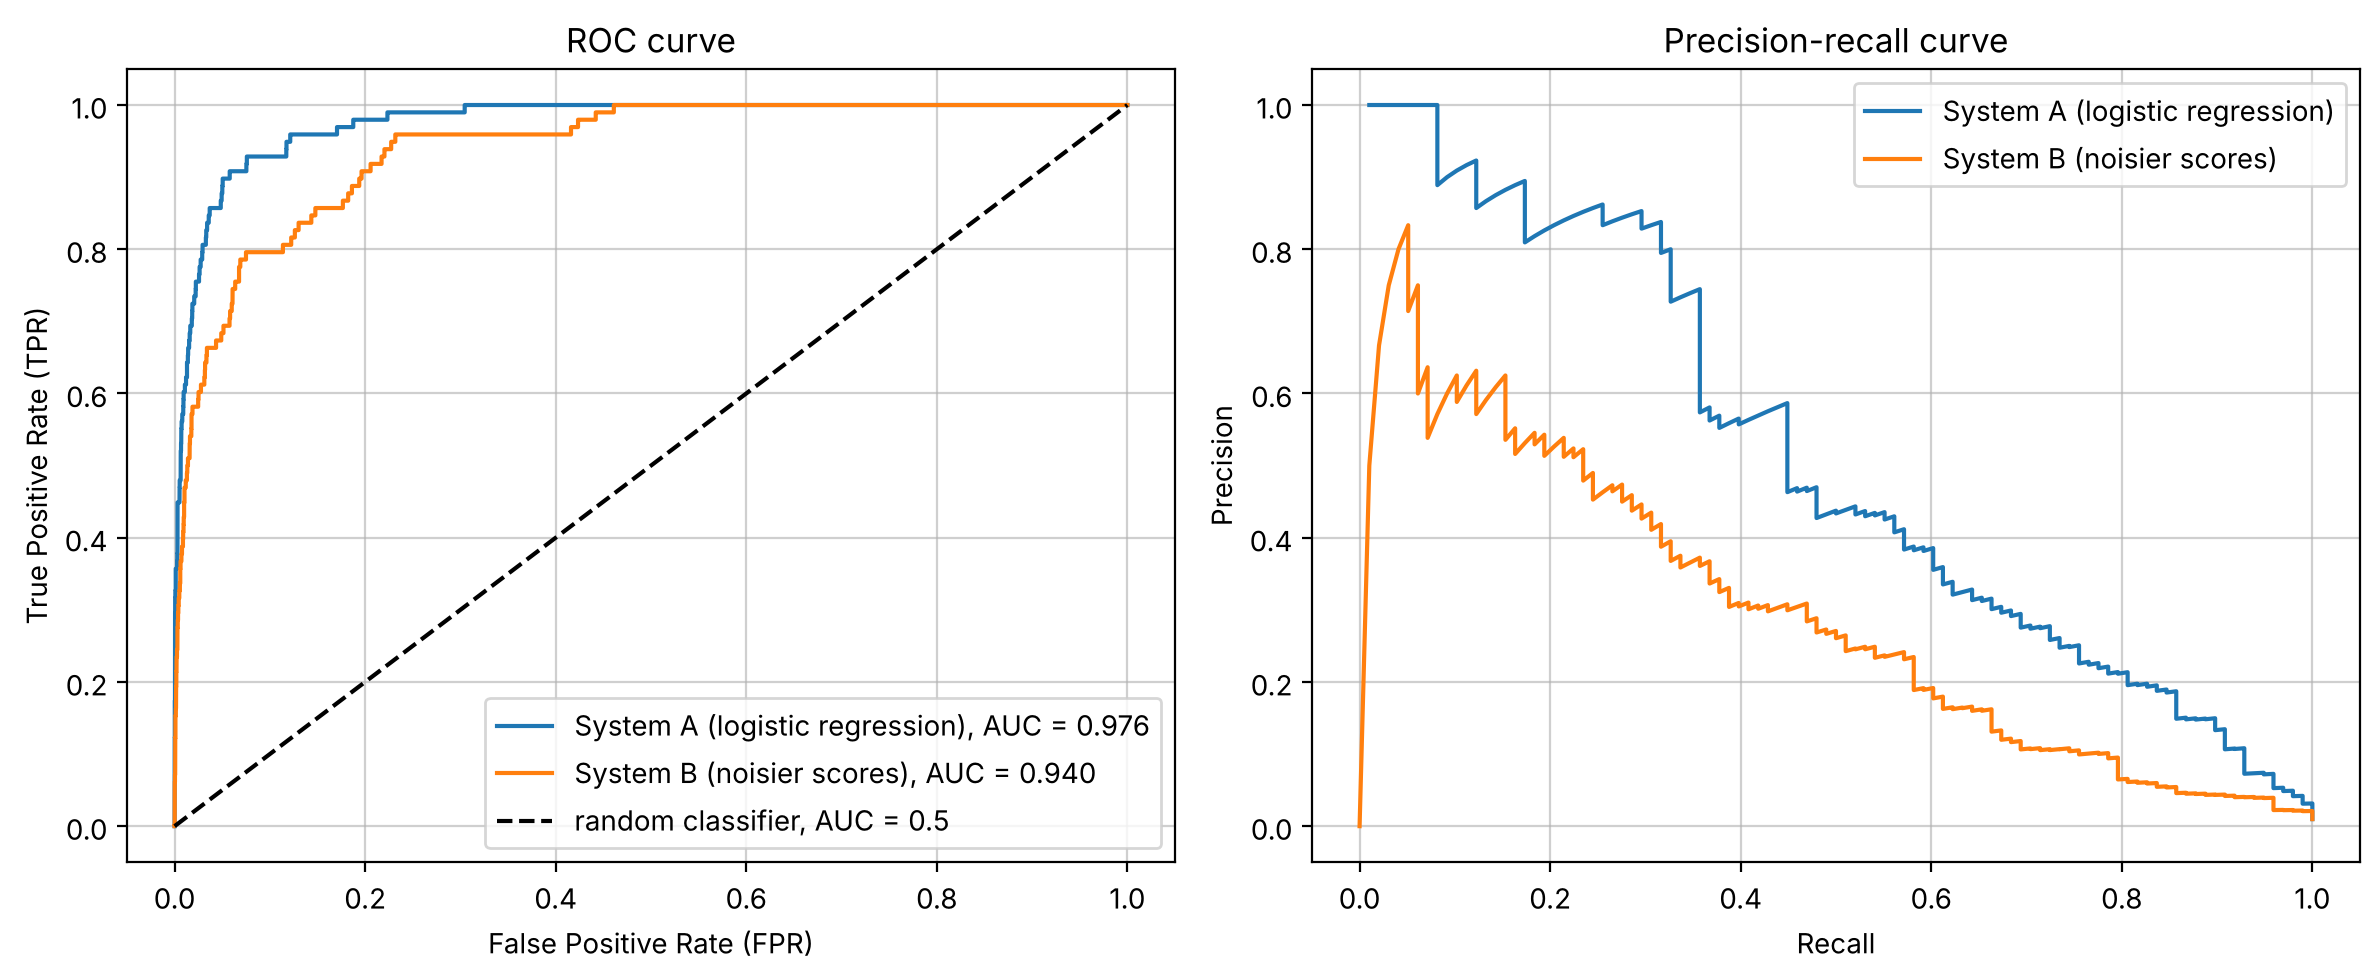

In [21]:
def roc_curve(y_true, scores):
    # sweep the threshold from high to low, so we start at (0, 0) and end at (1, 1)
    thresholds = np.concatenate([[np.inf], np.sort(np.unique(scores))[::-1]])
    P, Nn = np.sum(y_true == 1), np.sum(y_true == 0)
    tpr = np.array([np.sum((scores >= t) & (y_true == 1)) / P for t in thresholds])
    fpr = np.array([np.sum((scores >= t) & (y_true == 0)) / Nn for t in thresholds])
    return fpr, tpr, thresholds

def auc(fpr, tpr):
    # trapezium rule
    return np.sum(np.diff(fpr) * (tpr[1:] + tpr[:-1]) / 2)

# a weaker classifier for comparison: the same score with extra noise added
rng = np.random.default_rng(8)
p_weak = sigmoid(X_dis @ w_dis + rng.normal(0, 2, N))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for scores, name in [(p_dis, "System A (logistic regression)"), (p_weak, "System B (noisier scores)")]:
    fpr, tpr, thr = roc_curve(y_dis, scores)
    axes[0].plot(fpr, tpr, label=f"{name}, AUC = {auc(fpr, tpr):.3f}")
    # precision-recall curve from the same sweep (skip the first point where nothing is predicted positive)
    prec = np.array([precision_recall(y_dis, (scores >= t).astype(int))[0] for t in thr[1:]])
    axes[1].plot(tpr[1:], prec, label=name)

axes[0].plot([0, 1], [0, 1], "k--", label="random classifier, AUC = 0.5")
axes[0].set_xlabel("False Positive Rate (FPR)")
axes[0].set_ylabel("True Positive Rate (TPR)")
axes[0].set_title("ROC curve")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-recall curve")
for ax in axes:
    ax.legend(loc="lower right" if ax is axes[0] else "upper right")
    ax.grid(True, alpha=0.6)
plt.tight_layout()

System A's ROC curve is above System B's everywhere, so it has the higher AUC. Notice that on this very imbalanced data the precision-recall curve is much less flattering than the ROC curve, because even a small FPR means many false positives when 99% of patients are healthy.